In [11]:
from pathlib import Path
import json
import re
import ast

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 160)
pd.set_option("display.max_colwidth", 180)

# ------------------------------------------------------------
# Robust location of the user-study logs/ directory.
# Searches CWD, its parents, and their subtrees so the notebook
# runs whether launched from the data dir or from revision_outputs/.
# ------------------------------------------------------------
def _find_logs_dir():
    here = Path(".").resolve()
    # 1) direct hits: ./logs, ../logs, ../../logs
    for base in [here, *here.parents]:
        cand = base / "logs"
        if (cand / "notebook").is_dir() or (cand / "interface").is_dir() \
           or list(cand.glob("*Questionnaire*.csv")):
            return cand
    # 2) recursive fallback: find a logs/ that actually contains the data
    for base in [here, *here.parents][:4]:
        for cand in base.rglob("logs"):
            if (cand / "notebook").is_dir() or (cand / "interface").is_dir():
                return cand
    raise FileNotFoundError(
        "Could not locate a logs/ directory with notebook/ or interface/ data. "
        f"Searched from {here} upward.")

LOGS_DIR = _find_logs_dir()
DATA_ROOT = LOGS_DIR.parent          # where logs/ actually lives
NOTEBOOK_DIR = LOGS_DIR / "notebook"
INTERFACE_DIR = LOGS_DIR / "interface"
print("Resolved LOGS_DIR ->", LOGS_DIR)

# Keep analysis outputs next to where you launched (revision_outputs/),
# but fall back to DATA_ROOT if you prefer them beside the data.
ROOT = Path(".").resolve()
FIG_DIR = ROOT / "figures"
TABLE_DIR = ROOT / "tables"
PAPER_FIG_DIR = FIG_DIR
for d in [FIG_DIR, TABLE_DIR]:
    d.mkdir(parents=True, exist_ok=True)

notebook_json_files = sorted(NOTEBOOK_DIR.glob("*_answers.json"))
interface_json_files = sorted(INTERFACE_DIR.glob("*_interface_session.json"))
questionnaire_files = sorted(LOGS_DIR.glob("*Questionnaire*.csv"))

print("\nFiles used for analysis")
print("Notebook JSON files:", len(notebook_json_files))
print("Interface session JSON files:", len(interface_json_files))
print("Questionnaire CSV files:", len(questionnaire_files))

print("\nIgnored duplicate/raw files")
print("Notebook CSV files:", len(list(NOTEBOOK_DIR.glob("*_answers.csv"))))
print("Interface JSONL event files:", len(list(INTERFACE_DIR.glob("*_events.jsonl"))))

assert notebook_json_files or interface_json_files, \
    f"logs/ found at {LOGS_DIR} but no *_answers.json / *_interface_session.json inside."

Resolved LOGS_DIR -> /home/jovyan/fast/x_peer_pdt_hyperoptxai/user_study/logs

Files used for analysis
Notebook JSON files: 11
Interface session JSON files: 12
Questionnaire CSV files: 1

Ignored duplicate/raw files
Notebook CSV files: 11
Interface JSONL event files: 14


In [12]:
CONDITION_ORDER = ["API (A)", "Conversational (B)"]
TASK_ORDER = ["task_1", "task_2", "task_3"]

TASK_LABELS = {
    "task_1": "Task 1",
    "task_2": "Task 2",
    "task_3": "Task 3",
}

TASK_LABELS_LONG = {
    "task_1": "Task 1\nIndependent constraints",
    "task_2": "Task 2\nIndependent constraints",
    "task_3": "Task 3\nBaseline-relative",
}

CONDITION_COLORS = {
    "API (A)": "#4C78A8",
    "Conversational (B)": "#F58518",
}

LIKERT_ORDER = [
    "Strongly disagree",
    "Disagree",
    "Neutral",
    "Agree",
    "Strongly agree",
]

LIKERT_MAP = {
    "Strongly disagree": 1,
    "Disagree": 2,
    "Neutral": 3,
    "Agree": 4,
    "Strongly agree": 5,
}

QUESTION_ORDER = [
    "Identify valid F1",
    "Check constraints",
    "Understand trade-offs",
    "Compare options",
    "Use provided tool",
]

QUESTION_FULL_TEXT = {
    "Identify valid F1": "It was easy to identify configurations that satisfied the required F1 score.",
    "Check constraints": "It was easy to check whether the soft constraints were satisfied.",
    "Understand trade-offs": "It was easy to understand the trade-offs between predicted quality and soft constraints.",
    "Compare options": "It was easy to compare different configuration options.",
    "Use provided tool": "It was easy to use the provided resources to complete the tasks.",
}

QUESTION_PATTERNS = {
    "Identify valid F1": [
        ["f1", "target"],
        ["f1", "score"],
        ["required", "f1"],
    ],
    "Check constraints": [
        ["soft", "constraint"],
        ["constraints", "satisfied"],
    ],
    "Understand trade-offs": [
        ["trade"],
        ["quality", "soft"],
        ["performance", "soft"],
    ],
    "Compare options": [
        ["compare"],
        ["configuration", "options"],
    ],
    "Use provided tool": [
        ["resource"],
        ["provided", "resources"],
        ["provided", "tool"],
        ["tool", "complete"],
    ],
}


def read_json(path):
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)


def safe_get(d, key, default=None):
    return d.get(key, default) if isinstance(d, dict) else default


def clean_participant_id(x):
    if pd.isna(x):
        return np.nan
    x = str(x).strip()
    m = re.search(r"P-[A-Za-z0-9]+", x)
    return m.group(0).upper() if m else np.nan


def condition_label(x):
    mapping = {
        "condition_a": "API (A)",
        "condition_notebook": "API (A)",
        "notebook": "API (A)",
        "notebook_table": "API (A)",
        "condition_llm_interface": "Conversational (B)",
        "llm_interface": "Conversational (B)",
        "interface": "Conversational (B)",
    }
    return mapping.get(str(x), str(x))


def to_bool_or_na(x):
    if pd.isna(x):
        return pd.NA
    if isinstance(x, (bool, np.bool_)):
        return bool(x)
    s = str(x).strip().lower()
    if s in {"true", "1", "yes", "y"}:
        return True
    if s in {"false", "0", "no", "n"}:
        return False
    return pd.NA


def is_false_value(x):
    b = to_bool_or_na(x)
    return False if pd.isna(b) else (b is False)


def option_list_from_final_answers(data):
    if isinstance(data.get("final_answers"), list):
        return data.get("final_answers", [])
    if isinstance(data.get("final_answers_by_task"), dict):
        return list(data["final_answers_by_task"].values())
    return []


def extract_violated_constraints(row):
    explicit = row.get("violated_constraints", None)

    if isinstance(explicit, list):
        return [str(v) for v in explicit]

    if isinstance(explicit, str) and explicit.strip():
        try:
            parsed = ast.literal_eval(explicit)
            if isinstance(parsed, list):
                return [str(v) for v in parsed]
        except Exception:
            return [explicit]

    checks = {
        "quality_ok": "quality outside required range",
        "train_fraction_ok": "training fraction outside required range",
        "review_budget_ok": "review budget outside required range",
        "corruption_ok": "corruption level outside allowed values",
        "same_performance_ok": "quality lower than base configuration",
        "review_budget_5pct_lower_ok": "review budget not reduced by at least 5%",
        "different_from_base_ok": "same as base configuration",
    }

    violations = []
    for col, label in checks.items():
        if col in row.index and is_false_value(row.get(col)):
            violations.append(label)

    return violations


def save_table(df, name):
    csv_path = TABLE_DIR / f"{name}.csv"
    tex_path = TABLE_DIR / f"{name}.tex"

    df.to_csv(csv_path, index=False)

    try:
        df.to_latex(tex_path, index=False, escape=False)
    except Exception as exc:
        print(f"Could not save LaTeX table {tex_path}: {exc}")

    print("Saved table:", csv_path)
    return csv_path


def save_figure(fig, name):
    pdf_path = PAPER_FIG_DIR / f"{name}.pdf"
    png_path = PAPER_FIG_DIR / f"{name}.png"

    fig.savefig(pdf_path, bbox_inches="tight")
    fig.savefig(png_path, dpi=400, bbox_inches="tight")

    print("Saved figure:", pdf_path)
    print("Saved preview:", png_path)


# alias used in some cells
save_fig = save_figure


def colors_for_columns(columns):
    return [CONDITION_COLORS.get(c, "#777777") for c in columns]


def clean_likert_value(x):
    s = str(x).strip()
    s = re.sub(r"\s+", " ", s)

    canonical = {
        "strongly disagree": "Strongly disagree",
        "disagree": "Disagree",
        "neutral": "Neutral",
        "agree": "Agree",
        "strongly agree": "Strongly agree",
    }

    return canonical.get(s.lower(), s)


def normalise_text(x):
    return (
        str(x)
        .strip()
        .lower()
        .replace("–", "-")
        .replace("—", "-")
        .replace("\n", " ")
        .replace("\r", " ")
    )


def is_likert_column(series, min_valid=3, threshold=0.70):
    vals = series.dropna().map(clean_likert_value)
    if vals.empty:
        return False

    valid_count = vals.isin(LIKERT_ORDER).sum()
    valid_rate = valid_count / len(vals)

    return valid_count >= min_valid and valid_rate >= threshold


def detect_question_label(col_name):
    col_l = normalise_text(col_name)

    for label, pattern_groups in QUESTION_PATTERNS.items():
        for patterns in pattern_groups:
            if all(p in col_l for p in patterns):
                return label

    return None

In [13]:
notebook_rows = []
notebook_session_rows = []

for path in notebook_json_files:
    data = read_json(path)

    participant_id = data.get("participant_id")
    session_id = data.get("session_id")
    condition = data.get("study_condition", "condition_a")
    timing = data.get("timing", {})

    study_completion_seconds = timing.get("task_3_answered_at_relative_seconds")
    if study_completion_seconds is None:
        study_completion_seconds = timing.get("notebook_total_seconds_at_save")

    notebook_session_rows.append({
        "participant_id": participant_id,
        "session_id": session_id,
        "condition": condition,
        "source": "notebook",
        "study_completion_seconds": study_completion_seconds,
        "file_name": path.name,
    })

    for ans in data.get("answers", []):
        task = ans.get("task_name")

        notebook_rows.append({
            "participant_id": participant_id,
            "session_id": session_id,
            "condition": condition,
            "source": "notebook",
            "task_name": task,

            "selected_run_id": ans.get("run_id"),
            "selected_quality": ans.get("value"),
            "selected_review_budget": ans.get("params_soft_review_budget"),
            "selected_training_fraction": ans.get("params_soft_train_fraction"),
            "selected_corruption_level": ans.get("params_soft_corruption_level"),

            "valid_selection": ans.get("valid_selection"),
            "n_violations": ans.get("n_violations"),
            "confidence": ans.get("confidence"),
            "justification": ans.get("justification"),

            "relative_seconds": timing.get(f"{task}_answered_at_relative_seconds"),
            "elapsed_seconds": timing.get(f"{task}_elapsed_seconds"),
            "attempt_count": timing.get(f"{task}_attempt_count"),

            "base_run_id": ans.get("base_run_id"),
            "base_quality_score": ans.get("base_quality_score"),
            "base_review_budget": ans.get("base_review_budget"),
            "base_training_fraction": ans.get("base_training_fraction"),
            "base_corruption_level": ans.get("base_corruption_level"),

            "quality_ok": ans.get("quality_ok"),
            "train_fraction_ok": ans.get("train_fraction_ok"),
            "review_budget_ok": ans.get("review_budget_ok"),
            "corruption_ok": ans.get("corruption_ok"),
            "same_performance_ok": ans.get("same_performance_ok"),
            "review_budget_5pct_lower_ok": ans.get("review_budget_5pct_lower_ok"),
            "different_from_base_ok": ans.get("different_from_base_ok"),

            "quality_drop_from_base": ans.get("quality_drop_from_base"),
            "quality_change_from_base": ans.get("quality_change_from_base"),
            "review_budget_reduction_absolute": ans.get("review_budget_reduction_absolute"),
            "review_budget_reduction_percent": ans.get("review_budget_reduction_percent"),
            "valid_what_if": ans.get("valid_what_if"),
            "violated_constraints": ans.get("violated_constraints"),

            "file_name": path.name,
        })

notebook_answers = pd.DataFrame(notebook_rows)
notebook_sessions = pd.DataFrame(notebook_session_rows)

print("Notebook answers:", notebook_answers.shape)
print("Notebook sessions:", notebook_sessions.shape)
display(notebook_sessions.head())
display(notebook_answers.head())

Notebook answers: (33, 36)
Notebook sessions: (11, 6)


,participant_id,session_id,condition,source,study_completion_seconds,file_name
0,P-0D65E0,20260513_111102,condition_a,notebook,2410.68,P-0D65E0_20260513_111102_condition_a_answers.json
1,P-195051,20260513_111420,condition_a,notebook,887.27,P-195051_20260513_111420_condition_a_answers.json
2,P-31837D,20260513_112553,condition_a,notebook,803.77,P-31837D_20260513_112553_condition_a_answers.json
3,P-690100,20260513_112320,condition_a,notebook,3491.45,P-690100_20260513_112320_condition_a_answers.json
4,P-8AB788,20260527_111539,condition_a,notebook,896.84,P-8AB788_20260527_111539_condition_a_answers.json


,participant_id,session_id,condition,source,task_name,selected_run_id,selected_quality,selected_review_budget,selected_training_fraction,selected_corruption_level,valid_selection,n_violations,confidence,justification,relative_seconds,elapsed_seconds,attempt_count,base_run_id,base_quality_score,base_review_budget,base_training_fraction,base_corruption_level,quality_ok,train_fraction_ok,review_budget_ok,corruption_ok,same_performance_ok,review_budget_5pct_lower_ok,different_from_base_ok,quality_drop_from_base,quality_change_from_base,review_budget_reduction_absolute,review_budget_reduction_percent,valid_what_if,violated_constraints,file_name
0,P-0D65E0,20260513_111102,condition_a,notebook,task_1,1098,0.843800,0.370,0.56,mild,True,0,medium,"This model has just a little lower quality score than 1213 , but it is the only one with mild confidence. Its review budget isn't too high (like 0.4).",2032.69,2032.69,3,NaN,NaN,NaN,NaN,None,True,True,True,True,None,None,None,NaN,None,NaN,NaN,None,None,P-0D65E0_20260513_111102_condition_a_answers.json
1,P-0D65E0,20260513_111102,condition_a,notebook,task_2,1317,0.823985,0.250,0.32,none,True,0,high,It has the highest quality score from valid ones and the lowest review budget.,2207.53,174.84,2,NaN,NaN,NaN,NaN,None,True,True,True,True,None,None,None,NaN,None,NaN,NaN,None,None,P-0D65E0_20260513_111102_condition_a_answers.json
2,P-0D65E0,20260513_111102,condition_a,notebook,task_3,2794,0.854015,0.285,0.87,none,True,0,medium,Review budget got way lower while making quality score higher and even lowering training fraction.,2410.68,2410.68,2,1889.0,0.84984,0.375,0.95,strong,None,None,None,None,True,True,True,-0.004175,None,0.09,0.24,True,None,P-0D65E0_20260513_111102_condition_a_answers.json
3,P-195051,20260513_111420,condition_a,notebook,task_1,1213,0.859425,0.375,0.55,none,True,0,low,I chose run ID 1213 because with the lowest training fraction we get very similar results to bigger fractions. The rest of the parameters don't vary that much but lower trainin...,425.07,425.07,1,NaN,NaN,NaN,NaN,None,True,True,True,True,None,None,None,NaN,None,NaN,NaN,None,None,P-195051_20260513_111420_condition_a_answers.json
4,P-195051,20260513_111420,condition_a,notebook,task_2,1317,0.823985,0.250,0.32,none,True,0,medium,Run ID 1317 had the highest quality score for training fraction and budget within the given criteria.,604.56,179.49,1,NaN,NaN,NaN,NaN,None,True,True,True,True,None,None,None,NaN,None,NaN,NaN,None,None,P-195051_20260513_111420_condition_a_answers.json


In [14]:
# NOTE: the answer/attempt/session frames built here are rebuilt by the
# next cell, which is the authoritative version; this cell is kept because
# it is the only place interface_events (interaction_log) is extracted.
interface_rows = []
interface_attempt_rows = []
interface_event_rows = []
interface_session_rows = []

for path in interface_json_files:
    data = read_json(path)

    participant_id = data.get("participant_id")
    session_id = data.get("session_id")
    condition = data.get("study_condition", "condition_llm_interface")
    final_answers = option_list_from_final_answers(data)

    # Full study completion time.
    # Interface relative_seconds is cumulative. Task 3 final submission is full study time.
    task3_answers = [a for a in final_answers if a.get("task_name") == "task_3"]
    if task3_answers:
        study_completion_seconds = task3_answers[-1].get("relative_seconds")
    else:
        study_completion_seconds = data.get("total_elapsed_seconds")

    interface_session_rows.append({
        "participant_id": participant_id,
        "session_id": session_id,
        "condition": condition,
        "source": "interface",
        "study_completion_seconds": study_completion_seconds,
        "file_name": path.name,
    })

    for ans in final_answers:
        interface_rows.append({
            "participant_id": participant_id,
            "session_id": session_id,
            "condition": condition,
            "source": "interface",
            "task_name": ans.get("task_name"),

            "selected_run_id": ans.get("selected_run_id"),
            "selected_option_name": ans.get("selected_option_name"),
            "selected_quality": ans.get("selected_quality"),
            "selected_review_budget": ans.get("selected_review_budget"),
            "selected_training_fraction": ans.get("selected_training_fraction"),
            "selected_corruption_level": ans.get("selected_corruption_level"),

            "valid_selection": ans.get("valid_selection"),
            "n_violations": ans.get("n_violations"),
            "confidence": ans.get("confidence"),
            "justification": ans.get("justification"),

            # Cumulative from interface session start. Do not compare as per-task duration.
            "relative_seconds": ans.get("relative_seconds"),
            "elapsed_seconds": ans.get("relative_seconds"),
            "attempt_count": ans.get("attempt_count_at_submission"),

            "quality_rank_within_displayed_options": ans.get("quality_rank_within_displayed_options"),
            "review_budget_rank_within_displayed_options": ans.get("review_budget_rank_within_displayed_options"),
            "training_fraction_rank_within_displayed_options": ans.get("training_fraction_rank_within_displayed_options"),

            "base_run_id": ans.get("base_run_id"),
            "base_quality_score": ans.get("base_quality_score"),
            "base_review_budget": ans.get("base_review_budget"),
            "base_training_fraction": ans.get("base_training_fraction"),
            "base_corruption_level": ans.get("base_corruption_level"),

            "quality_ok": ans.get("quality_ok"),
            "train_fraction_ok": ans.get("train_fraction_ok"),
            "review_budget_ok": ans.get("review_budget_ok"),
            "corruption_ok": ans.get("corruption_ok"),
            "same_performance_ok": ans.get("same_performance_ok"),
            "review_budget_5pct_lower_ok": ans.get("review_budget_5pct_lower_ok"),
            "different_from_base_ok": ans.get("different_from_base_ok"),

            "quality_drop_from_base": ans.get("quality_drop_from_base"),
            "quality_change_from_base": ans.get("quality_change_from_base"),
            "review_budget_reduction_absolute": ans.get("review_budget_reduction_absolute"),
            "review_budget_reduction_percent": ans.get("review_budget_reduction_percent"),
            "valid_what_if": ans.get("valid_what_if"),
            "violated_constraints": ans.get("violated_constraints"),

            "file_name": path.name,
        })

    for att in data.get("generated_attempts", []):
        anchor_runs = att.get("anchor_runs", [])
        first_anchor = anchor_runs[0] if len(anchor_runs) else {}

        interface_attempt_rows.append({
            "participant_id": participant_id,
            "session_id": session_id,
            "condition": condition,
            "source": "interface",
            "file_name": path.name,
            "task_name": att.get("task_name"),
            "attempt_number": att.get("attempt_number"),
            "relative_seconds": att.get("relative_seconds"),
            "timestamp": att.get("timestamp"),
            "user_text": att.get("user_text"),
            "n_options": att.get("n_options"),
            "openrouter_model_id": att.get("openrouter_model_id"),
            "n_valid_dataset_matches": safe_get(first_anchor, "n_valid_dataset_matches"),
        })

    # Use interaction_log from session JSON only. Do not read *_events.jsonl.
    for ev in data.get("interaction_log", []):
        interface_event_rows.append({
            "participant_id": participant_id,
            "session_id": session_id,
            "condition": condition,
            "source": "interface",
            "file_name": path.name,
            **ev,
        })

interface_answers = pd.DataFrame(interface_rows)
interface_attempts = pd.DataFrame(interface_attempt_rows)
interface_events = pd.DataFrame(interface_event_rows)
interface_sessions = pd.DataFrame(interface_session_rows)

print("Interface answers:", interface_answers.shape)
print("Interface sessions:", interface_sessions.shape)
display(interface_answers.head())

Interface answers: (36, 40)
Interface sessions: (12, 6)


,participant_id,session_id,condition,source,task_name,selected_run_id,selected_option_name,selected_quality,selected_review_budget,selected_training_fraction,selected_corruption_level,valid_selection,n_violations,confidence,justification,relative_seconds,elapsed_seconds,attempt_count,quality_rank_within_displayed_options,review_budget_rank_within_displayed_options,training_fraction_rank_within_displayed_options,base_run_id,base_quality_score,base_review_budget,base_training_fraction,base_corruption_level,quality_ok,train_fraction_ok,review_budget_ok,corruption_ok,same_performance_ok,review_budget_5pct_lower_ok,different_from_base_ok,quality_drop_from_base,quality_change_from_base,review_budget_reduction_absolute,review_budget_reduction_percent,valid_what_if,violated_constraints,file_name
0,P-153315,20260513_092353,condition_llm_interface,interface,task_1,None,Option C,0.843800,0.370,0.56,mild,True,0,high,It has lowest review budget,372.81,372.81,1,3,1,2,NaN,NaN,NaN,NaN,None,True,True,True,True,None,None,None,NaN,NaN,NaN,NaN,None,[],P-153315_20260513_092353_interface_session.json
1,P-153315,20260513_092353,condition_llm_interface,interface,task_2,None,Option A,0.823985,0.250,0.32,none,True,0,medium,lowest review budget,490.21,490.21,2,1,1,1,NaN,NaN,NaN,NaN,None,True,True,True,True,None,None,None,NaN,NaN,NaN,NaN,None,[],P-153315_20260513_092353_interface_session.json
2,P-153315,20260513_092353,condition_llm_interface,interface,task_3,None,Option B,0.855263,0.355,0.97,strong,True,0,high,"quality is like the same, train is almost the same with very high value though probably doesnt matter if whats written in the instruction about it is the only thing that matter...",1090.80,1090.80,9,2,1,3,1889.0,0.84984,0.375,0.95,strong,None,None,None,None,True,True,True,-0.005423,0.005423,0.02,0.053333,True,[],P-153315_20260513_092353_interface_session.json
3,P-1F7053,20260513_092710,condition_llm_interface,interface,task_1,None,Option C,0.809269,0.300,0.39,mild,False,1,medium,"although this model is the further from best specification, other alternative's corruption level were none, so i choosed this one as the most optimal to ensure the model would ...",420.93,420.93,2,3,2,3,NaN,NaN,NaN,NaN,None,True,False,True,True,None,None,None,NaN,NaN,NaN,NaN,None,[training fraction outside allowed range],P-1F7053_20260513_092710_interface_session.json
4,P-1F7053,20260513_092710,condition_llm_interface,interface,task_2,None,Option B,0.809269,0.300,0.39,mild,True,0,high,"i find this option the best due to good value meets, also is the one most balanced over all",660.42,660.42,3,2,3,3,NaN,NaN,NaN,NaN,None,True,True,True,True,None,None,None,NaN,NaN,NaN,NaN,None,[],P-1F7053_20260513_092710_interface_session.json


In [15]:
interface_rows = []
interface_attempt_rows = []
interface_session_rows = []

for path in interface_json_files:
    data = read_json(path)

    participant_id = data.get("participant_id")
    session_id = data.get("session_id")
    condition = data.get("study_condition", "condition_llm_interface")
    final_answers = option_list_from_final_answers(data)

    task3_answers = [a for a in final_answers if a.get("task_name") == "task_3"]

    if task3_answers:
        study_completion_seconds = task3_answers[-1].get("relative_seconds")
    else:
        study_completion_seconds = data.get("total_elapsed_seconds")

    interface_session_rows.append({
        "participant_id": participant_id,
        "session_id": session_id,
        "condition": condition,
        "source": "interface",
        "study_completion_seconds": study_completion_seconds,
        "file_name": path.name,
    })

    for ans in final_answers:
        interface_rows.append({
            "participant_id": participant_id,
            "session_id": session_id,
            "condition": condition,
            "source": "interface",
            "task_name": ans.get("task_name"),

            "selected_run_id": ans.get("selected_run_id", ans.get("run_id")),
            "selected_option_name": ans.get("selected_option_name"),
            "selected_quality": ans.get("selected_quality"),
            "selected_review_budget": ans.get("selected_review_budget"),
            "selected_training_fraction": ans.get("selected_training_fraction"),
            "selected_corruption_level": ans.get("selected_corruption_level"),

            "valid_selection": ans.get("valid_selection"),
            "n_violations": ans.get("n_violations"),
            "confidence": ans.get("confidence"),
            "justification": ans.get("justification"),

            "relative_seconds": ans.get("relative_seconds"),
            "elapsed_seconds": ans.get("relative_seconds"),
            "attempt_count": ans.get("attempt_count_at_submission"),

            "base_run_id": ans.get("base_run_id"),
            "base_quality_score": ans.get("base_quality_score"),
            "base_review_budget": ans.get("base_review_budget"),
            "base_training_fraction": ans.get("base_training_fraction"),
            "base_corruption_level": ans.get("base_corruption_level"),

            "quality_ok": ans.get("quality_ok"),
            "train_fraction_ok": ans.get("train_fraction_ok"),
            "review_budget_ok": ans.get("review_budget_ok"),
            "corruption_ok": ans.get("corruption_ok"),
            "same_performance_ok": ans.get("same_performance_ok"),
            "review_budget_5pct_lower_ok": ans.get("review_budget_5pct_lower_ok"),
            "different_from_base_ok": ans.get("different_from_base_ok"),

            "quality_drop_from_base": ans.get("quality_drop_from_base"),
            "quality_change_from_base": ans.get("quality_change_from_base"),
            "review_budget_reduction_absolute": ans.get("review_budget_reduction_absolute"),
            "review_budget_reduction_percent": ans.get("review_budget_reduction_percent"),
            "valid_what_if": ans.get("valid_what_if"),
            "violated_constraints": ans.get("violated_constraints"),

            "file_name": path.name,
        })

    for att in data.get("generated_attempts", []):
        anchor_runs = att.get("anchor_runs", [])
        first_anchor = anchor_runs[0] if len(anchor_runs) else {}

        interface_attempt_rows.append({
            "participant_id": participant_id,
            "session_id": session_id,
            "condition": condition,
            "source": "interface",
            "task_name": att.get("task_name"),
            "attempt_number": att.get("attempt_number"),
            "relative_seconds": att.get("relative_seconds"),
            "timestamp": att.get("timestamp"),
            "user_text": att.get("user_text"),
            "n_options": att.get("n_options"),
            "openrouter_model_id": att.get("openrouter_model_id"),
            "n_valid_dataset_matches": safe_get(first_anchor, "n_valid_dataset_matches"),
            "file_name": path.name,
        })

interface_answers = pd.DataFrame(interface_rows)
interface_attempts = pd.DataFrame(interface_attempt_rows)
interface_sessions = pd.DataFrame(interface_session_rows)

print("Interface answers:", interface_answers.shape)
print("Interface sessions:", interface_sessions.shape)
display(interface_sessions.head())
display(interface_answers.head())

Interface answers: (36, 37)
Interface sessions: (12, 6)


,participant_id,session_id,condition,source,study_completion_seconds,file_name
0,P-153315,20260513_092353,condition_llm_interface,interface,1090.80,P-153315_20260513_092353_interface_session.json
1,P-1F7053,20260513_092710,condition_llm_interface,interface,1079.38,P-1F7053_20260513_092710_interface_session.json
2,P-238CF3,20260513_092848,condition_llm_interface,interface,1410.09,P-238CF3_20260513_092848_interface_session.json
3,P-30C813,20260513_092413,condition_llm_interface,interface,963.37,P-30C813_20260513_092413_interface_session.json
4,P-3FA4E7,20260513_093053,condition_llm_interface,interface,1504.55,P-3FA4E7_20260513_093053_interface_session.json


,participant_id,session_id,condition,source,task_name,selected_run_id,selected_option_name,selected_quality,selected_review_budget,selected_training_fraction,selected_corruption_level,valid_selection,n_violations,confidence,justification,relative_seconds,elapsed_seconds,attempt_count,base_run_id,base_quality_score,base_review_budget,base_training_fraction,base_corruption_level,quality_ok,train_fraction_ok,review_budget_ok,corruption_ok,same_performance_ok,review_budget_5pct_lower_ok,different_from_base_ok,quality_drop_from_base,quality_change_from_base,review_budget_reduction_absolute,review_budget_reduction_percent,valid_what_if,violated_constraints,file_name
0,P-153315,20260513_092353,condition_llm_interface,interface,task_1,None,Option C,0.843800,0.370,0.56,mild,True,0,high,It has lowest review budget,372.81,372.81,1,NaN,NaN,NaN,NaN,None,True,True,True,True,None,None,None,NaN,NaN,NaN,NaN,None,[],P-153315_20260513_092353_interface_session.json
1,P-153315,20260513_092353,condition_llm_interface,interface,task_2,None,Option A,0.823985,0.250,0.32,none,True,0,medium,lowest review budget,490.21,490.21,2,NaN,NaN,NaN,NaN,None,True,True,True,True,None,None,None,NaN,NaN,NaN,NaN,None,[],P-153315_20260513_092353_interface_session.json
2,P-153315,20260513_092353,condition_llm_interface,interface,task_3,None,Option B,0.855263,0.355,0.97,strong,True,0,high,"quality is like the same, train is almost the same with very high value though probably doesnt matter if whats written in the instruction about it is the only thing that matter...",1090.80,1090.80,9,1889.0,0.84984,0.375,0.95,strong,None,None,None,None,True,True,True,-0.005423,0.005423,0.02,0.053333,True,[],P-153315_20260513_092353_interface_session.json
3,P-1F7053,20260513_092710,condition_llm_interface,interface,task_1,None,Option C,0.809269,0.300,0.39,mild,False,1,medium,"although this model is the further from best specification, other alternative's corruption level were none, so i choosed this one as the most optimal to ensure the model would ...",420.93,420.93,2,NaN,NaN,NaN,NaN,None,True,False,True,True,None,None,None,NaN,NaN,NaN,NaN,None,[training fraction outside allowed range],P-1F7053_20260513_092710_interface_session.json
4,P-1F7053,20260513_092710,condition_llm_interface,interface,task_2,None,Option B,0.809269,0.300,0.39,mild,True,0,high,"i find this option the best due to good value meets, also is the one most balanced over all",660.42,660.42,3,NaN,NaN,NaN,NaN,None,True,True,True,True,None,None,None,NaN,NaN,NaN,NaN,None,[],P-1F7053_20260513_092710_interface_session.json


In [16]:
# ============================================================
# Combine notebook + interface data into common analysis tables
# Run this BEFORE duplicate cleaning
# ============================================================

# ------------------------------------------------------------
# 1. Combine final task answers
# ------------------------------------------------------------

answer_parts = []

if "notebook_answers" in globals() and not notebook_answers.empty:
    answer_parts.append(notebook_answers.copy())

if "interface_answers" in globals() and not interface_answers.empty:
    answer_parts.append(interface_answers.copy())

if not answer_parts:
    raise ValueError("No answer data found. Run the notebook/interface loading cells first.")

answers = pd.concat(answer_parts, ignore_index=True)

# ------------------------------------------------------------
# 2. Combine session-level data
# ------------------------------------------------------------

session_parts = []

if "notebook_sessions" in globals() and not notebook_sessions.empty:
    session_parts.append(notebook_sessions.copy())

if "interface_sessions" in globals() and not interface_sessions.empty:
    session_parts.append(interface_sessions.copy())

if not session_parts:
    raise ValueError("No session data found. Run the notebook/interface loading cells first.")

sessions = pd.concat(session_parts, ignore_index=True)

# ------------------------------------------------------------
# 3. Standardise participant IDs and condition labels
# ------------------------------------------------------------

answers["participant_id"] = answers["participant_id"].apply(clean_participant_id)
sessions["participant_id"] = sessions["participant_id"].apply(clean_participant_id)

answers["condition_label"] = answers["condition"].apply(condition_label)
sessions["condition_label"] = sessions["condition"].apply(condition_label)

# ------------------------------------------------------------
# 4. Standardise task names
# ------------------------------------------------------------

answers["task_name"] = answers["task_name"].astype(str).str.strip().str.lower()

# Keep only expected tasks
answers = answers[answers["task_name"].isin(TASK_ORDER)].copy()

# ------------------------------------------------------------
# 5. Convert numeric columns
# ------------------------------------------------------------

numeric_answer_cols = [
    "selected_run_id",
    "selected_quality",
    "selected_review_budget",
    "selected_training_fraction",
    "n_violations",
    "confidence",
    "relative_seconds",
    "elapsed_seconds",
    "attempt_count",
    "base_run_id",
    "base_quality_score",
    "base_review_budget",
    "base_training_fraction",
    "quality_drop_from_base",
    "quality_change_from_base",
    "review_budget_reduction_absolute",
    "review_budget_reduction_percent",
]

for col in numeric_answer_cols:
    if col in answers.columns:
        answers[col] = pd.to_numeric(answers[col], errors="coerce")

numeric_session_cols = [
    "study_completion_seconds",
]

for col in numeric_session_cols:
    if col in sessions.columns:
        sessions[col] = pd.to_numeric(sessions[col], errors="coerce")

sessions["study_completion_minutes"] = sessions["study_completion_seconds"] / 60

# ------------------------------------------------------------
# 6. Convert boolean-like columns
# ------------------------------------------------------------

bool_cols = [
    "valid_selection",
    "quality_ok",
    "train_fraction_ok",
    "review_budget_ok",
    "corruption_ok",
    "same_performance_ok",
    "review_budget_5pct_lower_ok",
    "different_from_base_ok",
    "valid_what_if",
]

for col in bool_cols:
    if col in answers.columns:
        answers[col] = answers[col].apply(to_bool_or_na)

# ------------------------------------------------------------
# 7. Derived fields needed later
# ------------------------------------------------------------

answers["violated_constraint_list"] = answers.apply(extract_violated_constraints, axis=1)
answers["n_extracted_violations"] = answers["violated_constraint_list"].apply(len)

if "n_violations" not in answers.columns:
    answers["n_violations"] = answers["n_extracted_violations"]
else:
    answers["n_violations"] = answers["n_violations"].fillna(answers["n_extracted_violations"])

answers["justification"] = answers["justification"].fillna("").astype(str)

answers["justification_words"] = (
    answers["justification"]
    .str.strip()
    .str.split()
    .str.len()
)

if "quality_change_from_base" not in answers.columns:
    answers["quality_change_from_base"] = np.nan

if "quality_drop_from_base" in answers.columns:
    mask = (
        answers["quality_change_from_base"].isna()
        & answers["quality_drop_from_base"].notna()
    )
    answers.loc[mask, "quality_change_from_base"] = -answers.loc[mask, "quality_drop_from_base"]

if "review_budget_reduction_percent" in answers.columns:
    raw = answers["review_budget_reduction_percent"].copy()

    if raw.dropna().abs().max() <= 2:
        answers["review_budget_reduction_pct"] = 100 * raw
    else:
        answers["review_budget_reduction_pct"] = raw
else:
    answers["review_budget_reduction_pct"] = np.nan

# ------------------------------------------------------------
# 8. Quick checks
# ------------------------------------------------------------

print("Combined answers:", answers.shape)
print("Combined sessions:", sessions.shape)

print("\nAnswers by condition/task:")
display(
    answers
    .groupby(["condition_label", "task_name"])
    .size()
    .reset_index(name="n")
)

print("\nSessions by condition:")
display(
    sessions
    .groupby("condition_label")
    .agg(
        n_sessions=("session_id", "nunique"),
        n_participants=("participant_id", "nunique"),
        mean_completion_min=("study_completion_minutes", "mean"),
    )
    .reset_index()
    .round(3)
)

Combined answers: (69, 42)
Combined sessions: (23, 8)

Answers by condition/task:


,condition_label,task_name,n
0,API (A),task_1,11
1,API (A),task_2,11
2,API (A),task_3,11
3,Conversational (B),task_1,12
4,Conversational (B),task_2,13
5,Conversational (B),task_3,11



Sessions by condition:


,condition_label,n_sessions,n_participants,mean_completion_min
0,API (A),10,10,23.645
1,Conversational (B),12,12,23.314


In [17]:
# ============================================================
# Check and clean duplicates by FINAL ANSWERS
# Run after answers and sessions are combined and basic cleaning is done
# ============================================================

ANSWER_KEY = ["participant_id", "session_id", "condition_label", "task_name"]
SESSION_KEY = ["participant_id", "session_id", "condition_label"]

# ------------------------------------------------------------
# 1. Inspect duplicate final-answer rows
# ------------------------------------------------------------

answer_duplicates = (
    answers
    .groupby(ANSWER_KEY)
    .agg(
        n_rows=("file_name", "size"),
        files=("file_name", lambda x: sorted(x.dropna().astype(str).unique().tolist())),
        selected_run_ids=("selected_run_id", lambda x: sorted(x.dropna().astype(str).unique().tolist())),
        selected_qualities=("selected_quality", lambda x: sorted(x.dropna().round(6).astype(str).unique().tolist())),
        selected_budgets=("selected_review_budget", lambda x: sorted(x.dropna().round(6).astype(str).unique().tolist())),
        valid_values=("valid_selection", lambda x: sorted(x.dropna().astype(str).unique().tolist())),
    )
    .reset_index()
    .query("n_rows > 1")
)

print("Duplicate final-answer keys:", len(answer_duplicates))
display(answer_duplicates)

# Show the actual duplicate rows in detail
if not answer_duplicates.empty:
    duplicate_keys = answer_duplicates[ANSWER_KEY]

    duplicate_answer_rows = answers.merge(
        duplicate_keys,
        on=ANSWER_KEY,
        how="inner",
    ).sort_values(ANSWER_KEY + ["file_name"])

    cols_to_show = [
        "participant_id",
        "session_id",
        "condition_label",
        "task_name",
        "file_name",
        "selected_run_id",
        "selected_quality",
        "selected_review_budget",
        "selected_training_fraction",
        "selected_corruption_level",
        "valid_selection",
        "n_violations",
        "attempt_count",
        "relative_seconds",
        "justification",
    ]

    cols_to_show = [c for c in cols_to_show if c in duplicate_answer_rows.columns]

    print("\nDetailed duplicate answer rows:")
    display(duplicate_answer_rows[cols_to_show])
else:
    print("No duplicate final-answer rows found.")

# ------------------------------------------------------------
# 2. Inspect duplicate sessions
# ------------------------------------------------------------

session_duplicates = (
    sessions
    .groupby(SESSION_KEY)
    .agg(
        n_rows=("file_name", "size"),
        files=("file_name", lambda x: sorted(x.dropna().astype(str).unique().tolist())),
        completion_times=("study_completion_minutes", lambda x: sorted(x.dropna().round(4).astype(str).unique().tolist())),
    )
    .reset_index()
    .query("n_rows > 1")
)

print("\nDuplicate session keys:", len(session_duplicates))
display(session_duplicates)

if not session_duplicates.empty:
    duplicate_session_rows = sessions.merge(
        session_duplicates[SESSION_KEY],
        on=SESSION_KEY,
        how="inner",
    ).sort_values(SESSION_KEY + ["file_name"])

    cols_to_show = [
        "participant_id",
        "session_id",
        "condition_label",
        "source",
        "study_completion_seconds",
        "study_completion_minutes",
        "file_name",
    ]

    cols_to_show = [c for c in cols_to_show if c in duplicate_session_rows.columns]

    print("\nDetailed duplicate session rows:")
    display(duplicate_session_rows[cols_to_show])
else:
    print("No duplicate session rows found.")

# ------------------------------------------------------------
# 3. Clean duplicate final answers and duplicate sessions consistently
# ------------------------------------------------------------

answers_before = len(answers)
sessions_before = len(sessions)

answers = (
    answers
    .sort_values(["condition_label", "participant_id", "session_id", "task_name", "file_name"])
    .drop_duplicates(subset=ANSWER_KEY, keep="last")
    .reset_index(drop=True)
)

sessions = (
    sessions
    .sort_values(["condition_label", "participant_id", "session_id", "file_name"])
    .drop_duplicates(subset=SESSION_KEY, keep="last")
    .reset_index(drop=True)
)

answers_after = len(answers)
sessions_after = len(sessions)

print("\nRows removed from answers:", answers_before - answers_after)
print("Rows removed from sessions:", sessions_before - sessions_after)

# ------------------------------------------------------------
# 4. Recompute extracted violations and derived fields after cleaning
# ------------------------------------------------------------

answers["violated_constraint_list"] = answers.apply(extract_violated_constraints, axis=1)
answers["n_extracted_violations"] = answers["violated_constraint_list"].apply(len)

if "n_violations" not in answers.columns:
    answers["n_violations"] = answers["n_extracted_violations"]
else:
    answers["n_violations"] = answers["n_violations"].fillna(answers["n_extracted_violations"])

answers["justification_words"] = (
    answers["justification"]
    .fillna("")
    .astype(str)
    .str.split()
    .str.len()
)

if "quality_change_from_base" not in answers.columns:
    answers["quality_change_from_base"] = np.nan

if "quality_drop_from_base" in answers.columns:
    mask = answers["quality_change_from_base"].isna() & answers["quality_drop_from_base"].notna()
    answers.loc[mask, "quality_change_from_base"] = -answers.loc[mask, "quality_drop_from_base"]

if "review_budget_reduction_percent" in answers.columns:
    raw = answers["review_budget_reduction_percent"].copy()
    if raw.dropna().abs().max() <= 2:
        answers["review_budget_reduction_pct"] = 100 * raw
    else:
        answers["review_budget_reduction_pct"] = raw
else:
    answers["review_budget_reduction_pct"] = np.nan

# ------------------------------------------------------------
# 5. Final count checks
# ------------------------------------------------------------

print("\n=== FINAL CLEAN COUNTS ===")

session_counts = (
    sessions
    .groupby("condition_label")
    .agg(
        n_sessions=("session_id", "nunique"),
        n_participants=("participant_id", "nunique"),
        n_completion_records=("study_completion_minutes", lambda s: s.notna().sum()),
    )
    .reset_index()
)

display(session_counts)

answer_counts = (
    answers
    .groupby(["condition_label", "task_name"])
    .agg(
        n_rows=("participant_id", "size"),
        n_participants=("participant_id", "nunique"),
    )
    .reset_index()
)

display(answer_counts)

print("\nParticipant IDs by condition:")
for condition in CONDITION_ORDER:
    ids = (
        sessions.loc[sessions["condition_label"] == condition, "participant_id"]
        .dropna()
        .drop_duplicates()
        .sort_values()
        .tolist()
    )
    print(f"{condition}: {len(ids)}")
    print(ids)

print("\nMissing task answers:")
expected_tasks = set(TASK_ORDER)
missing_rows = []

for (condition, participant), group in answers.groupby(["condition_label", "participant_id"]):
    observed = set(group["task_name"].dropna())
    missing = expected_tasks - observed

    if missing:
        missing_rows.append({
            "condition_label": condition,
            "participant_id": participant,
            "observed_tasks": sorted(observed),
            "missing_tasks": sorted(missing),
        })

missing_df = pd.DataFrame(missing_rows)
display(missing_df if not missing_df.empty else pd.DataFrame({"status": ["No missing task answers"]}))

Duplicate final-answer keys: 4


,participant_id,session_id,condition_label,task_name,n_rows,files,selected_run_ids,selected_qualities,selected_budgets,valid_values
21,P-3FA4E7,20260513_093053,Conversational (B),task_2,2,[P-3FA4E7_20260513_093053_interface_session.json],[],"[0.809269, 0.8438]","[0.3, 0.37]","[False, True]"
41,P-D166E1,20260513_112105,API (A),task_1,2,"[P-D166E1_20260513_112105_condition_a_answers.json, P-D2166E1_20260513_112105_condition_a_answers.json]",[965.0],[0.076471],[0.045],[False]
42,P-D166E1,20260513_112105,API (A),task_2,2,"[P-D166E1_20260513_112105_condition_a_answers.json, P-D2166E1_20260513_112105_condition_a_answers.json]",[2565.0],[0.906667],[0.345],[False]
43,P-D166E1,20260513_112105,API (A),task_3,2,"[P-D166E1_20260513_112105_condition_a_answers.json, P-D2166E1_20260513_112105_condition_a_answers.json]",[2730.0],[0.90084],[0.34],[True]



Detailed duplicate answer rows:


,participant_id,session_id,condition_label,task_name,file_name,selected_run_id,selected_quality,selected_review_budget,selected_training_fraction,selected_corruption_level,valid_selection,n_violations,attempt_count,relative_seconds,justification
6,P-3FA4E7,20260513_093053,Conversational (B),task_2,P-3FA4E7_20260513_093053_interface_session.json,NaN,0.843800,0.370,0.56,mild,False,1,2,1066.81,because of lowest review budget and i think that means that this reduces human effort so it can save more time.
7,P-3FA4E7,20260513_093053,Conversational (B),task_2,P-3FA4E7_20260513_093053_interface_session.json,NaN,0.809269,0.300,0.39,mild,True,0,6,1711.17,because it was training on more data than rest model.
0,P-D166E1,20260513_112105,API (A),task_1,P-D166E1_20260513_112105_condition_a_answers.json,965.0,0.076471,0.045,0.81,mild,False,2,3,1034.59,"If i undestend the task we must choose the one configuration with particulary configuration , sorry but now i read this heheh, okej but i will choice the most high score with t..."
1,P-D166E1,20260513_112105,API (A),task_1,P-D2166E1_20260513_112105_condition_a_answers.json,965.0,0.076471,0.045,0.81,mild,False,2,3,1034.59,"If i undestend the task we must choose the one configuration with particulary configuration , sorry but now i read this heheh, okej but i will choice the most high score with t..."
2,P-D166E1,20260513_112105,API (A),task_2,P-D166E1_20260513_112105_condition_a_answers.json,2565.0,0.906667,0.345,0.84,none,False,2,1,1084.96,"The same page to the lasted justification, the best quality_scorde and training fraction"
3,P-D166E1,20260513_112105,API (A),task_2,P-D2166E1_20260513_112105_condition_a_answers.json,2565.0,0.906667,0.345,0.84,none,False,2,1,1084.96,"The same page to the lasted justification, the best quality_scorde and training fraction"
4,P-D166E1,20260513_112105,API (A),task_3,P-D166E1_20260513_112105_condition_a_answers.json,2730.0,0.900840,0.340,0.91,none,True,0,2,1419.38,The configuration have most aproximate data to the base configuration
5,P-D166E1,20260513_112105,API (A),task_3,P-D2166E1_20260513_112105_condition_a_answers.json,2730.0,0.900840,0.340,0.91,none,True,0,2,1419.38,The configuration have most aproximate data to the base configuration



Duplicate session keys: 1


...


Rows removed from answers: 4
Rows removed from sessions: 1

=== FINAL CLEAN COUNTS ===


,condition_label,n_sessions,n_participants,n_completion_records
0,API (A),10,10,10
1,Conversational (B),12,12,12


,condition_label,task_name,n_rows,n_participants
0,API (A),task_1,10,10
1,API (A),task_2,10,10
2,API (A),task_3,10,10
3,Conversational (B),task_1,12,12
4,Conversational (B),task_2,12,12
5,Conversational (B),task_3,11,11



Participant IDs by condition:
API (A): 10
['P-0D65E0', 'P-195051', 'P-31837D', 'P-690100', 'P-8AB788', 'P-D166E1', 'P-E20F59', 'P-F4E531', 'P-FAD1DE', 'P-FB95A8']
Conversational (B): 12
['P-153315', 'P-1F7053', 'P-238CF3', 'P-30C813', 'P-3FA4E7', 'P-532DC7', 'P-58AFCB', 'P-C0C645', 'P-C519E1', 'P-DDBAAB', 'P-E13296', 'P-F283B6']

Missing task answers:


,condition_label,participant_id,observed_tasks,missing_tasks
0,Conversational (B),P-30C813,"[task_1, task_2]",[task_3]


In [18]:
def load_questionnaire_raw():
    if not questionnaire_files:
        return pd.DataFrame()

    parts = []
    for path in questionnaire_files:
        tmp = pd.read_csv(path)
        tmp["questionnaire_file"] = path.name
        parts.append(tmp)

    return pd.concat(parts, ignore_index=True)


def attach_condition_to_questionnaire(q_raw):
    q_clean = q_raw.copy()

    participant_candidates = [
        c for c in q_clean.columns
        if "participant" in str(c).lower()
        or "questionnaire" in str(c).lower()
        or str(c).strip().lower() in {"id", "participant id", "participant_id"}
    ]

    if not participant_candidates:
        raise ValueError("Could not detect participant ID column in questionnaire.")

    q_clean = q_clean.rename(columns={participant_candidates[0]: "participant_id"})
    q_clean["participant_id_raw"] = q_clean["participant_id"]
    q_clean["participant_id"] = q_clean["participant_id"].apply(clean_participant_id)

    n_raw = len(q_clean)

    q_clean = q_clean[
        q_clean["participant_id"].astype(str).str.match(r"^P-[A-Z0-9]+$", na=False)
    ].copy()
    n_valid_id = len(q_clean)

    # Deduplicate repeated submissions from the same participant (keep the
    # latest by Timestamp) so no participant is double-weighted in the
    # Likert means.
    ts_cols = [c for c in q_clean.columns if str(c).strip().lower() == "timestamp"]
    if ts_cols:
        q_clean = q_clean.sort_values(ts_cols[0])
    q_clean = q_clean.drop_duplicates(subset="participant_id", keep="last").copy()
    n_unique_valid = len(q_clean)

    participant_condition = (
        answers[["participant_id", "condition_label"]]
        .drop_duplicates()
        .dropna()
    )

    q_clean = q_clean.merge(participant_condition, on="participant_id", how="left")

    matched_mask = q_clean["condition_label"].isin(CONDITION_ORDER)

    global QUESTIONNAIRE_ACCOUNTING
    QUESTIONNAIRE_ACCOUNTING = {
        "raw_responses": int(n_raw),
        "removed_no_valid_id": int(n_raw - n_valid_id),
        "removed_duplicate_submissions": int(n_valid_id - n_unique_valid),
        "unique_valid_responses": int(n_unique_valid),
        "matched_by_condition": (
            q_clean.loc[matched_mask, "condition_label"].value_counts().to_dict()
        ),
        "unmatched_ids": q_clean.loc[~matched_mask, "participant_id"].tolist(),
    }

    print("\nQuestionnaire accounting:")
    for k, v in QUESTIONNAIRE_ACCOUNTING.items():
        print(f"- {k}: {v}")

    return q_clean


def build_questionnaire_long(q_raw):
    q_clean = attach_condition_to_questionnaire(q_raw)

    print("Raw questionnaire shape:", q_raw.shape)
    print("Clean questionnaire rows with valid participant ID:", q_clean.shape[0])
    print("Questionnaire rows without matched condition:", q_clean["condition_label"].isna().sum())

    detected = []

    for col in q_clean.columns:
        if col in {"participant_id", "participant_id_raw", "condition_label", "questionnaire_file"}:
            continue

        if is_likert_column(q_clean[col]):
            detected.append({
                "raw_col": col,
                "detected_label": detect_question_label(col),
                "valid_likert_count": int(q_clean[col].map(clean_likert_value).isin(LIKERT_ORDER).sum()),
                "non_null_count": int(q_clean[col].dropna().shape[0]),
            })

    detected_df = pd.DataFrame(detected)

    print("\nDetected Likert columns:")
    display(detected_df)

    used = set(detected_df["detected_label"].dropna()) if not detected_df.empty else set()
    remaining = [x for x in QUESTION_ORDER if x not in used]

    final_mapping = {}

    for _, row in detected_df.iterrows():
        raw_col = row["raw_col"]
        label = row["detected_label"]

        if label is None:
            label = remaining.pop(0) if remaining else f"Question {len(final_mapping) + 1}"

        if label in final_mapping.values():
            label = remaining.pop(0) if remaining else f"{label} duplicate"

        final_mapping[raw_col] = label

    print("\nFinal questionnaire mapping:")
    for raw_col, label in final_mapping.items():
        print(f"- {label}: {raw_col}")

    rows = []

    for raw_col, label in final_mapping.items():
        for _, row in q_clean.iterrows():
            answer = clean_likert_value(row.get(raw_col))
            score = LIKERT_MAP.get(answer, np.nan)

            rows.append({
                "participant_id": row.get("participant_id"),
                "condition_label": row.get("condition_label"),
                "question": label,
                "question_full": QUESTION_FULL_TEXT.get(label, label),
                "raw_question_column": raw_col,
                "answer": answer,
                "score": score,
            })

    q_long = pd.DataFrame(rows)
    q_long = q_long[
        q_long["condition_label"].isin(CONDITION_ORDER)
        & q_long["score"].notna()
    ].copy()

    return q_clean, q_long, detected_df, final_mapping


questionnaire_raw = load_questionnaire_raw()

if questionnaire_raw.empty:
    q_clean = pd.DataFrame()
    q_long = pd.DataFrame()
    detected_questions = pd.DataFrame()
    question_mapping = {}
    print("No questionnaire CSV found.")
else:
    q_clean, q_long, detected_questions, question_mapping = build_questionnaire_long(questionnaire_raw)

print("\nQuestionnaire responses by condition:")
if not q_long.empty:
    display(
        q_long[["participant_id", "condition_label"]]
        .drop_duplicates()
        .groupby("condition_label")
        .size()
        .reset_index(name="n_questionnaire_responses")
    )


Questionnaire accounting:
- raw_responses: 22
- removed_no_valid_id: 1
- removed_duplicate_submissions: 1
- unique_valid_responses: 20
- matched_by_condition: {'Conversational (B)': 11, 'API (A)': 9}
- unmatched_ids: []
Raw questionnaire shape: (22, 8)
Clean questionnaire rows with valid participant ID: 20
Questionnaire rows without matched condition: 0

Detected Likert columns:


,raw_col,detected_label,valid_likert_count,non_null_count
0,It was easy to: [Identify a configuration that satisfied the required F1 target.],Identify valid F1,20,20
1,It was easy to: [Check whether the soft constraints were satisfied.],Check constraints,20,20
2,It was easy to: [See the trade-offs between performance and soft constraints.],Check constraints,20,20
3,It was easy to: [Compare different configuration options.],Compare options,20,20
4,It was easy to: [Use the provided resources.],Use provided tool,20,20



Final questionnaire mapping:
- Identify valid F1: It was easy to: [Identify a configuration that satisfied the required F1 target.]
- Check constraints: It was easy to: [Check whether the soft constraints were satisfied.]
- Understand trade-offs: It was easy to: [See the trade-offs between performance and soft constraints.]
- Compare options: It was easy to: [Compare different configuration options.]
- Use provided tool: It was easy to: [Use the provided resources.]

Questionnaire responses by condition:


,condition_label,n_questionnaire_responses
0,API (A),9
1,Conversational (B),11


In [19]:
print("=== FILE COUNTS ===")
print("Notebook JSON files:", len(notebook_json_files))
print("Interface session JSON files:", len(interface_json_files))
print("Questionnaire CSV files:", len(questionnaire_files))

print("\n=== SESSIONS BY CONDITION ===")
session_counts = (
    sessions
    .groupby("condition_label")
    .agg(
        n_sessions=("session_id", "nunique"),
        n_participants=("participant_id", "nunique"),
        n_with_completion_time=("study_completion_minutes", lambda s: s.notna().sum()),
    )
    .reset_index()
)
display(session_counts)

print("\n=== FINAL ANSWERS BY CONDITION AND TASK ===")
answer_counts = (
    answers
    .groupby(["condition_label", "task_name"])
    .agg(
        n_rows=("participant_id", "size"),
        n_participants=("participant_id", "nunique"),
    )
    .reset_index()
)
display(answer_counts)

print("\n=== PARTICIPANT IDS BY CONDITION ===")
for condition in CONDITION_ORDER:
    ids = (
        sessions.loc[sessions["condition_label"] == condition, "participant_id"]
        .dropna()
        .drop_duplicates()
        .sort_values()
        .tolist()
    )
    print(f"{condition}: {len(ids)}")
    print(ids)

print("\n=== PARTICIPANTS WITH MISSING TASK ANSWERS ===")
expected_tasks = set(TASK_ORDER)
missing_rows = []

for (condition, participant), group in answers.groupby(["condition_label", "participant_id"]):
    observed = set(group["task_name"].dropna())
    missing = expected_tasks - observed

    if missing:
        missing_rows.append({
            "condition_label": condition,
            "participant_id": participant,
            "observed_tasks": sorted(observed),
            "missing_tasks": sorted(missing),
        })

missing_df = pd.DataFrame(missing_rows)
display(missing_df if not missing_df.empty else pd.DataFrame({"status": ["No missing task answers"]}))

print("\n=== QUESTIONNAIRE MATCHING ===")
if not q_long.empty:
    q_match_summary = (
        q_long[["participant_id", "condition_label"]]
        .drop_duplicates()
        .groupby("condition_label")
        .size()
        .reset_index(name="n_matched_questionnaire_responses")
    )
    display(q_match_summary)
else:
    print("No questionnaire data available.")

=== FILE COUNTS ===
Notebook JSON files: 11
Interface session JSON files: 12
Questionnaire CSV files: 1

=== SESSIONS BY CONDITION ===


,condition_label,n_sessions,n_participants,n_with_completion_time
0,API (A),10,10,10
1,Conversational (B),12,12,12



=== FINAL ANSWERS BY CONDITION AND TASK ===


,condition_label,task_name,n_rows,n_participants
0,API (A),task_1,10,10
1,API (A),task_2,10,10
2,API (A),task_3,10,10
3,Conversational (B),task_1,12,12
4,Conversational (B),task_2,12,12
5,Conversational (B),task_3,11,11



=== PARTICIPANT IDS BY CONDITION ===
API (A): 10
['P-0D65E0', 'P-195051', 'P-31837D', 'P-690100', 'P-8AB788', 'P-D166E1', 'P-E20F59', 'P-F4E531', 'P-FAD1DE', 'P-FB95A8']
Conversational (B): 12
['P-153315', 'P-1F7053', 'P-238CF3', 'P-30C813', 'P-3FA4E7', 'P-532DC7', 'P-58AFCB', 'P-C0C645', 'P-C519E1', 'P-DDBAAB', 'P-E13296', 'P-F283B6']

=== PARTICIPANTS WITH MISSING TASK ANSWERS ===


,condition_label,participant_id,observed_tasks,missing_tasks
0,Conversational (B),P-30C813,"[task_1, task_2]",[task_3]



=== QUESTIONNAIRE MATCHING ===


,condition_label,n_matched_questionnaire_responses
0,API (A),9
1,Conversational (B),11


,condition_label,n,mean_min,median_min,sd_min,min_min,max_min
0,API (A),10,23.64,18.34,14.69,11.58,58.19
1,Conversational (B),12,23.31,22.16,8.90,14.01,46.26


Saved table: /home/jovyan/fast/x_peer_pdt_hyperoptxai/hpo_pdt_dataset/tables/paper_completion_time_summary.csv


/tmp/ipykernel_89038/2006226466.py:176: FutureWarning: In future versions `DataFrame.to_latex` is expected to utilise the base implementation of `Styler.to_latex` for formatting and rendering. The arguments signature may therefore change. It is recommended instead to use `DataFrame.style.to_latex` which also contains additional functionality.
  df.to_latex(tex_path, index=False, escape=False)


Saved figure: /home/jovyan/fast/x_peer_pdt_hyperoptxai/hpo_pdt_dataset/figures/fig_1_completion_time_boxplot.pdf
Saved preview: /home/jovyan/fast/x_peer_pdt_hyperoptxai/hpo_pdt_dataset/figures/fig_1_completion_time_boxplot.png


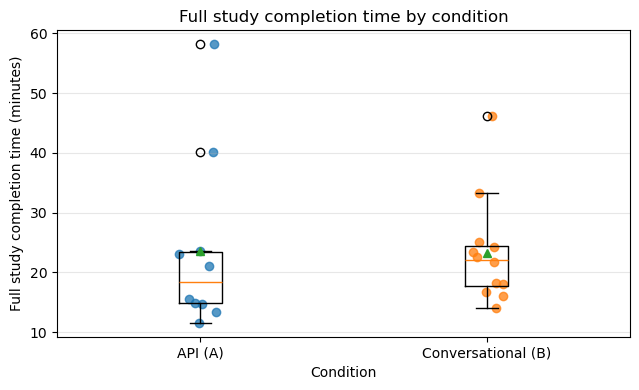

In [20]:
completion = sessions.copy()
completion = completion[completion["condition_label"].isin(CONDITION_ORDER)].copy()
completion["condition_label"] = pd.Categorical(
    completion["condition_label"],
    categories=CONDITION_ORDER,
    ordered=True
)
completion = completion.sort_values("condition_label")

completion_summary = (
    completion
    .groupby("condition_label", observed=False)
    .agg(
        n=("participant_id", "nunique"),
        mean_min=("study_completion_minutes", "mean"),
        median_min=("study_completion_minutes", "median"),
        sd_min=("study_completion_minutes", "std"),
        min_min=("study_completion_minutes", "min"),
        max_min=("study_completion_minutes", "max"),
    )
    .reset_index()
)

display(completion_summary.round(2))
save_table(completion_summary.round(4), "paper_completion_time_summary")

fig, ax = plt.subplots(figsize=(6.5, 4))

data_by_condition = [
    completion.loc[completion["condition_label"] == c, "study_completion_minutes"].dropna().values
    for c in CONDITION_ORDER
    if c in completion["condition_label"].dropna().unique()
]

labels = [
    c for c in CONDITION_ORDER
    if c in completion["condition_label"].dropna().unique()
]

ax.boxplot(data_by_condition, tick_labels=labels, showmeans=True)

# Add individual points for transparency
for i, values in enumerate(data_by_condition, start=1):
    x = np.random.normal(i, 0.035, size=len(values))
    ax.scatter(x, values, alpha=0.75)

ax.set_ylabel("Full study completion time (minutes)")
ax.set_xlabel("Condition")
ax.set_title("Full study completion time by condition")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
save_fig(fig, "fig_1_completion_time_boxplot")
plt.show()

In [21]:
# ------------------------------------------------------------
# Sample and completion time
# ------------------------------------------------------------

completion_summary = (
    sessions[sessions["condition_label"].isin(CONDITION_ORDER)]
    .groupby("condition_label")
    .agg(
        logged_sessions=("session_id", "nunique"),
        logged_participants=("participant_id", "nunique"),
        completion_n=("study_completion_minutes", lambda s: s.notna().sum()),
        mean_min=("study_completion_minutes", "mean"),
        median_min=("study_completion_minutes", "median"),
        sd_min=("study_completion_minutes", "std"),
        min_min=("study_completion_minutes", "min"),
        max_min=("study_completion_minutes", "max"),
    )
    .reset_index()
)

final_answer_counts = (
    answers
    .groupby("condition_label")
    .size()
    .reset_index(name="usable_final_answers")
)

completion_summary = completion_summary.merge(
    final_answer_counts,
    on="condition_label",
    how="left"
)

completion_summary["condition_label"] = pd.Categorical(
    completion_summary["condition_label"],
    categories=CONDITION_ORDER,
    ordered=True,
)
completion_summary = completion_summary.sort_values("condition_label")

display(completion_summary.round(3))
save_table(completion_summary.round(4), "paper_sample_and_completion_time")


# ------------------------------------------------------------
# Task-level validity and selections
# ------------------------------------------------------------

task_summary = (
    answers
    .groupby(["condition_label", "task_name"])
    .agg(
        n=("participant_id", "nunique"),
        n_rows=("participant_id", "size"),
        valid_selection_rate=("valid_selection", "mean"),
        mean_violations=("n_violations", "mean"),
        mean_attempts=("attempt_count", "mean"),
        mean_quality=("selected_quality", "mean"),
        mean_review_budget=("selected_review_budget", "mean"),
        mean_training_fraction=("selected_training_fraction", "mean"),
    )
    .reset_index()
)

task_summary["valid_selection_rate_pct"] = 100 * task_summary["valid_selection_rate"]

task_summary["condition_label"] = pd.Categorical(
    task_summary["condition_label"],
    categories=CONDITION_ORDER,
    ordered=True,
)
task_summary["task_name"] = pd.Categorical(
    task_summary["task_name"],
    categories=TASK_ORDER,
    ordered=True,
)

task_summary = task_summary.sort_values(["condition_label", "task_name"])

display(task_summary.round(3))
save_table(task_summary.round(4), "paper_task_level_summary")


# ------------------------------------------------------------
# Violation summary
# ------------------------------------------------------------

violation_rows = []

for _, row in answers.iterrows():
    for violation in row.get("violated_constraint_list", []):
        violation_rows.append({
            "participant_id": row["participant_id"],
            "condition_label": row["condition_label"],
            "task_name": row["task_name"],
            "violation": violation,
        })

violations_long = pd.DataFrame(violation_rows)

if violations_long.empty:
    violation_summary = pd.DataFrame(columns=["condition_label", "task_name", "violation", "count"])
else:
    violation_summary = (
        violations_long
        .groupby(["condition_label", "task_name", "violation"])
        .size()
        .reset_index(name="count")
        .sort_values(["condition_label", "task_name", "count"], ascending=[True, True, False])
    )

display(violation_summary)
save_table(violation_summary, "paper_violation_summary")


# ------------------------------------------------------------
# Task 3 what-if summary
# ------------------------------------------------------------

task3 = answers[answers["task_name"] == "task_3"].copy()

if "valid_what_if" not in task3.columns or task3["valid_what_if"].isna().all():
    task3["valid_what_if_for_summary"] = task3["valid_selection"]
else:
    task3["valid_what_if_for_summary"] = task3["valid_what_if"].fillna(task3["valid_selection"])

task3_summary = (
    task3
    .groupby("condition_label")
    .agg(
        n=("participant_id", "nunique"),
        valid_selection_rate=("valid_selection", "mean"),
        valid_what_if_rate=("valid_what_if_for_summary", "mean"),
        mean_selected_quality=("selected_quality", "mean"),
        mean_base_quality=("base_quality_score", "mean"),
        mean_quality_change=("quality_change_from_base", "mean"),
        median_quality_change=("quality_change_from_base", "median"),
        mean_selected_review_budget=("selected_review_budget", "mean"),
        mean_base_review_budget=("base_review_budget", "mean"),
        mean_budget_reduction_pct=("review_budget_reduction_pct", "mean"),
        median_budget_reduction_pct=("review_budget_reduction_pct", "median"),
        mean_selected_training_fraction=("selected_training_fraction", "mean"),
    )
    .reset_index()
)

task3_summary["valid_selection_rate_pct"] = 100 * task3_summary["valid_selection_rate"]
task3_summary["valid_what_if_rate_pct"] = 100 * task3_summary["valid_what_if_rate"]

task3_summary["condition_label"] = pd.Categorical(
    task3_summary["condition_label"],
    categories=CONDITION_ORDER,
    ordered=True,
)
task3_summary = task3_summary.sort_values("condition_label")

display(task3_summary.round(3))
save_table(task3_summary.round(4), "paper_task3_what_if_summary")


# ------------------------------------------------------------
# Questionnaire summary
# ------------------------------------------------------------

if not q_long.empty:
    questionnaire_summary = (
        q_long
        .groupby(["question", "question_full", "condition_label"])
        .agg(
            n=("score", "count"),
            mean=("score", "mean"),
            sd=("score", "std"),
            median=("score", "median"),
        )
        .reset_index()
    )

    questionnaire_summary["question"] = pd.Categorical(
        questionnaire_summary["question"],
        categories=[q for q in QUESTION_ORDER if q in q_long["question"].unique()],
        ordered=True,
    )
    questionnaire_summary["condition_label"] = pd.Categorical(
        questionnaire_summary["condition_label"],
        categories=CONDITION_ORDER,
        ordered=True,
    )

    questionnaire_summary = questionnaire_summary.sort_values(["question", "condition_label"])

    display(questionnaire_summary.round(3))
    save_table(questionnaire_summary.round(4), "paper_questionnaire_summary")

    questionnaire_pivot = (
        questionnaire_summary
        .pivot_table(
            index=["question", "question_full"],
            columns="condition_label",
            values="mean",
            aggfunc="mean",
        )
        .reset_index()
    )

    cond_a, cond_b = CONDITION_ORDER[0], CONDITION_ORDER[1]
    if cond_a in questionnaire_pivot.columns and cond_b in questionnaire_pivot.columns:
        questionnaire_pivot["mean_difference_B_minus_A"] = (
            questionnaire_pivot[cond_b] - questionnaire_pivot[cond_a]
        )

    display(questionnaire_pivot.round(3))
    save_table(questionnaire_pivot.round(4), "paper_questionnaire_mean_comparison")
else:
    questionnaire_summary = pd.DataFrame()
    questionnaire_pivot = pd.DataFrame()
    print("No questionnaire summary generated.")


# ------------------------------------------------------------
# Justification length summary
# ------------------------------------------------------------

justification_summary = (
    answers
    .groupby(["condition_label", "task_name"])
    .agg(
        mean_justification_words=("justification_words", "mean"),
        median_justification_words=("justification_words", "median"),
    )
    .reset_index()
)

justification_summary["condition_label"] = pd.Categorical(
    justification_summary["condition_label"],
    categories=CONDITION_ORDER,
    ordered=True,
)
justification_summary["task_name"] = pd.Categorical(
    justification_summary["task_name"],
    categories=TASK_ORDER,
    ordered=True,
)
justification_summary = justification_summary.sort_values(["condition_label", "task_name"])

display(justification_summary.round(2))
save_table(justification_summary.round(2), "paper_justification_length_summary")

,condition_label,logged_sessions,logged_participants,completion_n,mean_min,median_min,sd_min,min_min,max_min,usable_final_answers
0,API (A),10,10,10,23.643,18.342,14.694,11.576,58.191,30
1,Conversational (B),12,12,12,23.314,22.160,8.897,14.008,46.258,35


Saved table: /home/jovyan/fast/x_peer_pdt_hyperoptxai/hpo_pdt_dataset/tables/paper_sample_and_completion_time.csv


/tmp/ipykernel_89038/2006226466.py:176: FutureWarning: In future versions `DataFrame.to_latex` is expected to utilise the base implementation of `Styler.to_latex` for formatting and rendering. The arguments signature may therefore change. It is recommended instead to use `DataFrame.style.to_latex` which also contains additional functionality.
  df.to_latex(tex_path, index=False, escape=False)


,condition_label,task_name,n,n_rows,valid_selection_rate,mean_violations,mean_attempts,mean_quality,mean_review_budget,mean_training_fraction,valid_selection_rate_pct
0,API (A),task_1,10,10,0.900,0.200,1.600,0.773,0.340,0.581,90.000
1,API (A),task_2,10,10,0.900,0.200,1.200,0.831,0.264,0.379,90.000
2,API (A),task_3,10,10,0.900,0.100,1.200,0.875,0.318,0.880,90.000
3,Conversational (B),task_1,12,12,0.833,0.167,1.583,0.851,0.370,0.543,83.333
4,Conversational (B),task_2,12,12,1.000,0.000,3.500,0.818,0.271,0.349,100.000
5,Conversational (B),task_3,11,11,0.818,0.273,6.273,0.883,0.361,0.895,81.818


Saved table: /home/jovyan/fast/x_peer_pdt_hyperoptxai/hpo_pdt_dataset/tables/paper_task_level_summary.csv


...

/tmp/ipykernel_89038/2006226466.py:176: FutureWarning: In future versions `DataFrame.to_latex` is expected to utilise the base implementation of `Styler.to_latex` for formatting and rendering. The arguments signature may therefore change. It is recommended instead to use `DataFrame.style.to_latex` which also contains additional functionality.
  df.to_latex(tex_path, index=False, escape=False)


,condition_label,task_name,mean_justification_words,median_justification_words
0,API (A),task_1,25.70,23.0
1,API (A),task_2,21.70,15.5
2,API (A),task_3,23.30,12.0
3,Conversational (B),task_1,29.33,19.0
4,Conversational (B),task_2,23.17,21.5
5,Conversational (B),task_3,30.18,19.0


Saved table: /home/jovyan/fast/x_peer_pdt_hyperoptxai/hpo_pdt_dataset/tables/paper_justification_length_summary.csv


/tmp/ipykernel_89038/2006226466.py:176: FutureWarning: In future versions `DataFrame.to_latex` is expected to utilise the base implementation of `Styler.to_latex` for formatting and rendering. The arguments signature may therefore change. It is recommended instead to use `DataFrame.style.to_latex` which also contains additional functionality.
  df.to_latex(tex_path, index=False, escape=False)


PosixPath('/home/jovyan/fast/x_peer_pdt_hyperoptxai/hpo_pdt_dataset/tables/paper_justification_length_summary.csv')

,condition_label,task_name,violation,count
0,API (A),task_1,quality outside required range,1
1,API (A),task_1,training fraction outside required range,1
2,API (A),task_2,review budget outside required range,1
3,API (A),task_2,training fraction outside required range,1
4,API (A),task_3,quality lower than base configuration,1
5,Conversational (B),task_1,training fraction outside allowed range,2
7,Conversational (B),task_3,review budget not reduced by at least 5%,2
6,Conversational (B),task_3,quality lower than base configuration,1


Saved table: /home/jovyan/fast/x_peer_pdt_hyperoptxai/hpo_pdt_dataset/tables/paper_violation_type_summary.csv


/tmp/ipykernel_89038/2006226466.py:176: FutureWarning: In future versions `DataFrame.to_latex` is expected to utilise the base implementation of `Styler.to_latex` for formatting and rendering. The arguments signature may therefore change. It is recommended instead to use `DataFrame.style.to_latex` which also contains additional functionality.
  df.to_latex(tex_path, index=False, escape=False)


Saved figure: /home/jovyan/fast/x_peer_pdt_hyperoptxai/hpo_pdt_dataset/figures/fig_3_constraint_violation_profile.pdf
Saved preview: /home/jovyan/fast/x_peer_pdt_hyperoptxai/hpo_pdt_dataset/figures/fig_3_constraint_violation_profile.png


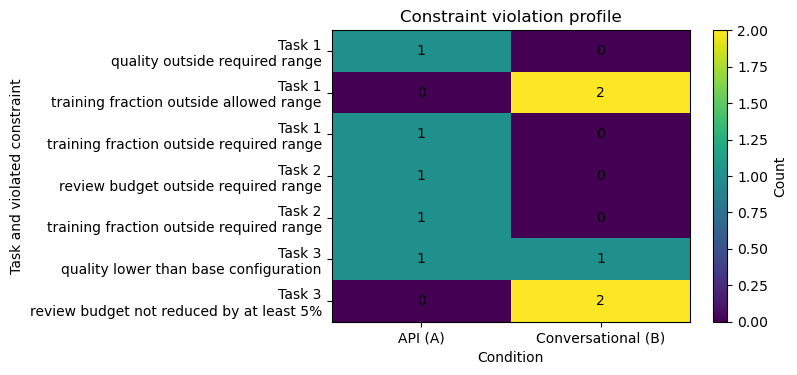

In [22]:
violation_rows = []

for _, row in answers.iterrows():
    violations = row.get("violated_constraint_list", [])
    if not isinstance(violations, list):
        violations = []

    for v in violations:
        violation_rows.append({
            "participant_id": row["participant_id"],
            "condition_label": row["condition_label"],
            "task_name": row["task_name"],
            "violation": str(v),
        })

violations_long = pd.DataFrame(violation_rows)

if violations_long.empty:
    print("No violations found.")
    violation_summary = pd.DataFrame()
else:
    violation_summary = (
        violations_long
        .groupby(["condition_label", "task_name", "violation"])
        .size()
        .reset_index(name="count")
        .sort_values(["condition_label", "task_name", "count"], ascending=[True, True, False])
    )

    display(violation_summary)
    save_table(violation_summary, "paper_violation_type_summary")

    # Compact heatmap: rows = task + violation, columns = condition
    heat = (
        violation_summary
        .assign(task_violation=lambda d: d["task_name"].map(TASK_LABELS) + "\n" + d["violation"])
        .pivot_table(
            index="task_violation",
            columns="condition_label",
            values="count",
            aggfunc="sum",
            fill_value=0
        )
    )

    heat = heat.reindex(columns=[c for c in CONDITION_ORDER if c in heat.columns])

    fig, ax = plt.subplots(figsize=(8, max(3.5, 0.55 * len(heat))))

    im = ax.imshow(heat.values, aspect="auto")

    ax.set_xticks(np.arange(len(heat.columns)))
    ax.set_xticklabels(heat.columns)

    ax.set_yticks(np.arange(len(heat.index)))
    ax.set_yticklabels(heat.index)

    ax.set_title("Constraint violation profile")
    ax.set_xlabel("Condition")
    ax.set_ylabel("Task and violated constraint")

    # Annotate cells
    for i in range(heat.shape[0]):
        for j in range(heat.shape[1]):
            value = int(heat.iloc[i, j])
            ax.text(j, i, value, ha="center", va="center")

    plt.colorbar(im, ax=ax, label="Count")
    plt.tight_layout()
    save_fig(fig, "fig_3_constraint_violation_profile")
    plt.show()

Saved figure: /home/jovyan/fast/x_peer_pdt_hyperoptxai/hpo_pdt_dataset/figures/fig_user_study_valid_selection_rate.pdf
Saved preview: /home/jovyan/fast/x_peer_pdt_hyperoptxai/hpo_pdt_dataset/figures/fig_user_study_valid_selection_rate.png


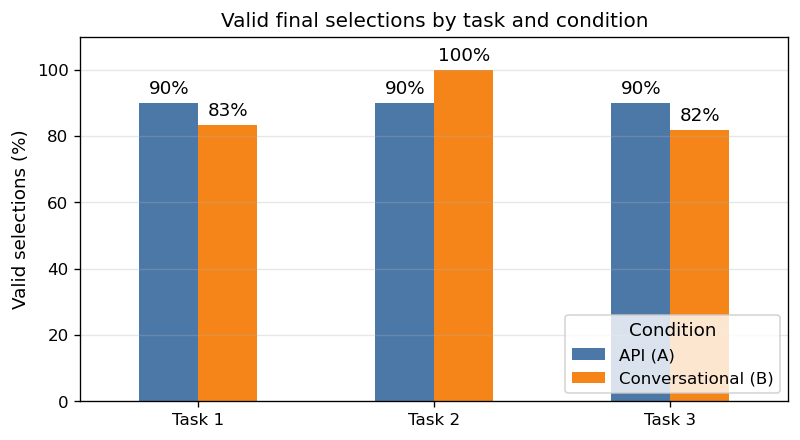

Saved figure: /home/jovyan/fast/x_peer_pdt_hyperoptxai/hpo_pdt_dataset/figures/fig_user_study_task3_quality_budget_tradeoff.pdf
Saved preview: /home/jovyan/fast/x_peer_pdt_hyperoptxai/hpo_pdt_dataset/figures/fig_user_study_task3_quality_budget_tradeoff.png


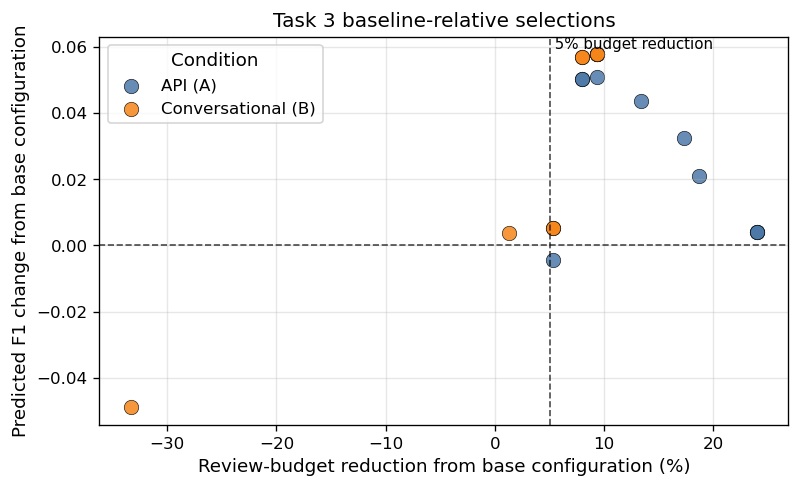

Saved figure: /home/jovyan/fast/x_peer_pdt_hyperoptxai/hpo_pdt_dataset/figures/fig_user_study_questionnaire_all_items.pdf
Saved preview: /home/jovyan/fast/x_peer_pdt_hyperoptxai/hpo_pdt_dataset/figures/fig_user_study_questionnaire_all_items.png


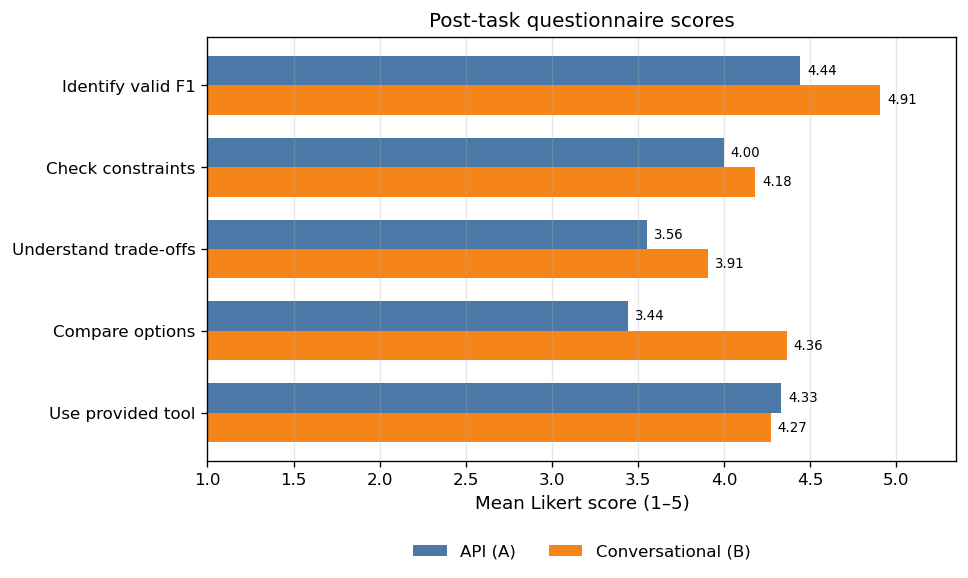


Main paper figures saved in: /home/jovyan/fast/x_peer_pdt_hyperoptxai/hpo_pdt_dataset/figures


In [28]:
plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
})


# ------------------------------------------------------------
# Figure 1: Valid selection rate
# ------------------------------------------------------------

pivot_valid = (
    task_summary
    .pivot(index="task_name", columns="condition_label", values="valid_selection_rate_pct")
    .reindex(TASK_ORDER)
)

pivot_valid.index = [TASK_LABELS[t] for t in pivot_valid.index]
pivot_valid = pivot_valid[[c for c in CONDITION_ORDER if c in pivot_valid.columns]]

fig, ax = plt.subplots(figsize=(6.8, 3.8))

pivot_valid.plot(
    kind="bar",
    ax=ax,
    color=colors_for_columns(pivot_valid.columns),
)

ax.set_ylabel("Valid selections (%)")
ax.set_xlabel("")
ax.set_ylim(0, 110)
ax.set_title("Valid final selections by task and condition")
ax.legend(title="Condition", loc="lower right")
ax.grid(axis="y", alpha=0.3)
plt.xticks(rotation=0)

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f%%", padding=3)

plt.tight_layout()
save_figure(fig, "fig_user_study_valid_selection_rate")
plt.show()


# ------------------------------------------------------------
# Figure 2: Task 3 quality-budget trade-off
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(6.8, 4.2))

for condition in CONDITION_ORDER:
    sub = task3[task3["condition_label"] == condition]
    if sub.empty:
        continue

    ax.scatter(
        sub["review_budget_reduction_pct"],
        sub["quality_change_from_base"],
        s=75,
        alpha=0.85,
        label=condition,
        color=CONDITION_COLORS[condition],
        edgecolor="black",
        linewidth=0.4,
    )

ax.axhline(0, linestyle="--", linewidth=1, color="black", alpha=0.7)
ax.axvline(5, linestyle="--", linewidth=1, color="black", alpha=0.7)

ax.set_xlabel("Review-budget reduction from base configuration (%)")
ax.set_ylabel("Predicted F1 change from base configuration")
ax.set_title("Task 3 baseline-relative selections")
ax.legend(title="Condition")
ax.grid(alpha=0.3)

y_top = ax.get_ylim()[1]
ax.text(
    5,
    y_top,
    " 5% budget reduction",
    va="top",
    ha="left",
    fontsize=9,
)

plt.tight_layout()
save_figure(fig, "fig_user_study_task3_quality_budget_tradeoff")
plt.show()


# ------------------------------------------------------------
# Figure 3: Questionnaire scores
# ------------------------------------------------------------

if not questionnaire_summary.empty:
    plot_df = (
        questionnaire_summary
        .pivot_table(
            index="question",
            columns="condition_label",
            values="mean",
            aggfunc="mean",
        )
        .reindex([q for q in QUESTION_ORDER if q in questionnaire_summary["question"].astype(str).unique()])
    )

    plot_df = plot_df[[c for c in CONDITION_ORDER if c in plot_df.columns]]

    fig, ax = plt.subplots(figsize=(8.2, 5.0))

    y = np.arange(len(plot_df.index))
    bar_h = 0.36

    plotted_conditions = list(plot_df.columns)
    offsets = (
        np.linspace(-bar_h / 2, bar_h / 2, num=len(plotted_conditions))
        if len(plotted_conditions) > 1
        else [0]
    )

    for offset, condition in zip(offsets, plotted_conditions):
        vals = plot_df[condition].values

        ax.barh(
            y + offset,
            vals,
            height=bar_h,
            label=condition,
            color=CONDITION_COLORS.get(condition, "#777777"),
        )

        for yi, val in zip(y + offset, vals):
            if pd.notna(val):
                ax.text(
                    val + 0.04,
                    yi,
                    f"{val:.2f}",
                    va="center",
                    ha="left",
                    fontsize=8,
                )

    ax.set_yticks(y)
    ax.set_yticklabels(plot_df.index)
    ax.set_xlim(1, 5.35)
    ax.set_xlabel("Mean Likert score (1–5)")
    ax.set_ylabel("")
    ax.set_title("Post-task questionnaire scores")
    ax.legend(
        title=None,
        loc="upper center",
        bbox_to_anchor=(0.5, -0.16),
        ncol=2,
        frameon=False,
    )
    
    ax.grid(axis="x", alpha=0.3)
    ax.invert_yaxis()

    plt.tight_layout()
    save_figure(fig, "fig_user_study_questionnaire_all_items")
    plt.show()
else:
    print("Questionnaire figure skipped: no questionnaire summary available.")


print("\nMain paper figures saved in:", PAPER_FIG_DIR)

In [24]:
# ============================================================
# Extract participant comments / justifications for LLM summary
# ============================================================

COMMENT_EXPORT_DIR = TABLE_DIR / "qualitative_comments"
COMMENT_EXPORT_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 1. Extract task justifications from final answers
# ------------------------------------------------------------

comment_df = answers.copy()

comment_df["comment_text"] = (
    comment_df["justification"]
    .fillna("")
    .astype(str)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

comment_df = comment_df[comment_df["comment_text"].ne("")].copy()

comment_df["task_label"] = comment_df["task_name"].map(TASK_LABELS).fillna(comment_df["task_name"])
comment_df["condition_label"] = comment_df["condition_label"].astype(str)

# Keep useful context, but avoid exposing raw session/file identifiers to the LLM.
comment_df["participant_code"] = (
    comment_df["condition_label"]
    .str.replace("/", "_", regex=False)
    .str.replace("(", "", regex=False)
    .str.replace(")", "", regex=False)
    .str.replace(" ", "_", regex=False)
    + "_P"
    + comment_df.groupby("condition_label")["participant_id"].transform(
        lambda s: pd.factorize(s)[0] + 1
    ).astype(str)
)

comment_cols = [
    "participant_code",
    "condition_label",
    "task_name",
    "task_label",
    "valid_selection",
    "n_violations",
    "selected_quality",
    "selected_review_budget",
    "selected_training_fraction",
    "selected_corruption_level",
    "quality_change_from_base",
    "review_budget_reduction_pct",
    "comment_text",
    "justification_words",
]

comment_cols = [c for c in comment_cols if c in comment_df.columns]
comment_export = comment_df[comment_cols].copy()

comment_export = comment_export.sort_values(
    ["condition_label", "participant_code", "task_name"]
).reset_index(drop=True)

display(comment_export)

comments_csv = COMMENT_EXPORT_DIR / "user_study_task_justifications.csv"
comments_jsonl = COMMENT_EXPORT_DIR / "user_study_task_justifications.jsonl"
comments_md = COMMENT_EXPORT_DIR / "user_study_task_justifications_for_llm.md"

comment_export.to_csv(comments_csv, index=False)

with open(comments_jsonl, "w", encoding="utf-8") as f:
    for record in comment_export.to_dict(orient="records"):
        f.write(json.dumps(record, ensure_ascii=False) + "\n")

print("Saved comments CSV:", comments_csv)
print("Saved comments JSONL:", comments_jsonl)


# ------------------------------------------------------------
# 2. Build a readable Markdown file for LLM input
# ------------------------------------------------------------

lines = []

lines.append("# User Study Participant Justifications")
lines.append("")
lines.append(
    "These comments are participant-written justifications for their final selected "
    "configuration in each task. Participant identifiers are anonymised."
)
lines.append("")
lines.append("## Context")
lines.append("")
lines.append("- Condition `API (A)`: participants interacted with the recommendation pipeline through its Python API in a Jupyter notebook, with criteria specified in code and results returned as data tables.")
lines.append("- Condition `Conversational (B)`: participants used the conversational counterfactual guidance interface.")
lines.append("- Task 1 and Task 2 involved absolute (independent) constraints.")
lines.append("- Task 3 involved constraints defined relative to a base configuration.")
lines.append("")
lines.append("## Comments")
lines.append("")

for condition in CONDITION_ORDER:
    sub_condition = comment_export[comment_export["condition_label"] == condition].copy()

    if sub_condition.empty:
        continue

    lines.append(f"### Condition: {condition}")
    lines.append("")

    for task in TASK_ORDER:
        sub_task = sub_condition[sub_condition["task_name"] == task].copy()

        if sub_task.empty:
            continue

        task_label = TASK_LABELS.get(task, task)
        lines.append(f"#### {task_label}")
        lines.append("")

        for _, row in sub_task.iterrows():
            valid_text = "valid" if bool(row.get("valid_selection")) else "invalid"

            context_bits = [
                f"participant={row.get('participant_code')}",
                f"selection={valid_text}",
            ]

            if pd.notna(row.get("selected_quality", np.nan)):
                context_bits.append(f"F1={float(row['selected_quality']):.3f}")

            if pd.notna(row.get("selected_review_budget", np.nan)):
                context_bits.append(f"review_budget={float(row['selected_review_budget']):.3f}")

            if pd.notna(row.get("selected_training_fraction", np.nan)):
                context_bits.append(f"train_fraction={float(row['selected_training_fraction']):.3f}")

            if row.get("selected_corruption_level", None) not in [None, "", np.nan]:
                context_bits.append(f"corruption={row.get('selected_corruption_level')}")

            if task == "task_3":
                if pd.notna(row.get("quality_change_from_base", np.nan)):
                    context_bits.append(f"delta_F1={float(row['quality_change_from_base']):.3f}")

                if pd.notna(row.get("review_budget_reduction_pct", np.nan)):
                    context_bits.append(
                        f"budget_reduction_pct={float(row['review_budget_reduction_pct']):.2f}"
                    )

            lines.append(f"- ({'; '.join(context_bits)}) {row['comment_text']}")

        lines.append("")

comments_md.write_text("\n".join(lines), encoding="utf-8")

print("Saved LLM-ready Markdown:", comments_md)


# ------------------------------------------------------------
# 3. Build an LLM prompt file for later qualitative summary
# ------------------------------------------------------------

llm_prompt = f"""
You are analysing participant comments from a user study comparing two systems:
1. API baseline (condition A): pipeline used through its Python API in a notebook
2. Conversational interface (condition B)

The comments are short participant justifications for selected machine-learning configurations.
Summarise them for an academic paper subsection under Human-Centred Evaluation.

Focus on:
- how participants justified their choices;
- whether they mention F1 score, review budget, training fraction, corruption level, or trade-offs;
- differences between the API (A) and conversational interface (B) conditions;
- specific observations for Task 3, which required reasoning against a base configuration (baseline-relative constraints);
- any signs of confusion, over-focus on predicted F1, or difficulty with relative review-budget reduction.

Do not overclaim. Treat the analysis as qualitative and descriptive.
Do not identify participants.
Use concise academic language.

Suggested output structure:
1. Short paragraph summarising the overall pattern.
2. Paragraph comparing the two conditions.
3. Paragraph about Task 3 and baseline-relative reasoning.
4. Two or three cautious implications for interface design.

Use the following comments as evidence:

{comments_md.read_text(encoding="utf-8")}
""".strip()

prompt_path = COMMENT_EXPORT_DIR / "llm_prompt_for_qualitative_summary.txt"
prompt_path.write_text(llm_prompt, encoding="utf-8")

print("Saved LLM prompt:", prompt_path)


# ------------------------------------------------------------
# 4. Quick descriptive statistics for paper support
# ------------------------------------------------------------

comment_summary = (
    comment_export
    .groupby(["condition_label", "task_label"])
    .agg(
        n_comments=("comment_text", "count"),
        mean_words=("justification_words", "mean"),
        median_words=("justification_words", "median"),
    )
    .reset_index()
)

display(comment_summary.round(2))

comment_summary_path = COMMENT_EXPORT_DIR / "user_study_comment_summary.csv"
comment_summary.to_csv(comment_summary_path, index=False)

print("Saved comment summary:", comment_summary_path)

,participant_code,condition_label,task_name,task_label,valid_selection,n_violations,selected_quality,selected_review_budget,selected_training_fraction,selected_corruption_level,quality_change_from_base,review_budget_reduction_pct,comment_text,justification_words
0,API_A_P1,API (A),task_1,Task 1,True,0,0.843800,0.370,0.56,mild,NaN,NaN,"This model has just a little lower quality score than 1213 , but it is the only one with mild confidence. Its review budget isn't too high (like 0.4).",29
1,API_A_P1,API (A),task_2,Task 2,True,0,0.823985,0.250,0.32,none,NaN,NaN,It has the highest quality score from valid ones and the lowest review budget.,14
2,API_A_P1,API (A),task_3,Task 3,True,0,0.854015,0.285,0.87,none,0.004175,24.000000,Review budget got way lower while making quality score higher and even lowering training fraction.,15
3,API_A_P10,API (A),task_1,Task 1,True,0,0.843800,0.370,0.56,mild,NaN,NaN,It satisfies all constraints. It has high F1 score and lower review budget.,13
4,API_A_P10,API (A),task_2,Task 2,True,0,0.823985,0.250,0.32,none,NaN,NaN,"It fits the constraints. It has the highest F1 score from fitting options, lowest review budget and lowest training fraction.",20
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
60,Conversational_B_P8,Conversational (B),task_2,Task 2,True,0,0.823985,0.250,0.32,none,NaN,NaN,The option A is a balanced choice - the only drawback is that corruption level is none,17
61,Conversational_B_P8,Conversational (B),task_3,Task 3,True,0,0.907563,0.340,0.90,none,0.057723,9.333333,A is the best quality and lowest review budget which was our goal,13
62,Conversational_B_P9,Conversational (B),task_1,Task 1,True,0,0.859425,0.375,0.55,none,NaN,NaN,It has better quality than the others and the review budget does not differ that much from C,18
63,Conversational_B_P9,Conversational (B),task_2,Task 2,True,0,0.823985,0.250,0.32,none,NaN,NaN,It is the best in every column,7


Saved comments CSV: /home/jovyan/fast/x_peer_pdt_hyperoptxai/hpo_pdt_dataset/tables/qualitative_comments/user_study_task_justifications.csv
Saved comments JSONL: /home/jovyan/fast/x_peer_pdt_hyperoptxai/hpo_pdt_dataset/tables/qualitative_comments/user_study_task_justifications.jsonl
Saved LLM-ready Markdown: /home/jovyan/fast/x_peer_pdt_hyperoptxai/hpo_pdt_dataset/tables/qualitative_comments/user_study_task_justifications_for_llm.md
Saved LLM prompt: /home/jovyan/fast/x_peer_pdt_hyperoptxai/hpo_pdt_dataset/tables/qualitative_comments/llm_prompt_for_qualitative_summary.txt


,condition_label,task_label,n_comments,mean_words,median_words
0,API (A),Task 1,10,25.70,23.0
1,API (A),Task 2,10,21.70,15.5
2,API (A),Task 3,10,23.30,12.0
3,Conversational (B),Task 1,12,29.33,19.0
4,Conversational (B),Task 2,12,23.17,21.5
5,Conversational (B),Task 3,11,30.18,19.0


Saved comment summary: /home/jovyan/fast/x_peer_pdt_hyperoptxai/hpo_pdt_dataset/tables/qualitative_comments/user_study_comment_summary.csv


In [25]:
print("=== COPY THESE VALUES INTO THE PAPER ===")

print("\n1) File/session counts")
print("Notebook JSON files:", len(notebook_json_files))
print("Interface session JSON files:", len(interface_json_files))
print("Questionnaire CSV files:", len(questionnaire_files))

print("\n2) Analysed sessions and completion time")
display(completion_summary.round(2))

print("\n3) Task-level summary")
display(task_summary.round(3))

print("\n4) Task 3 baseline-relative summary")
display(task3_summary.round(3))

print("\n5) Questionnaire summary")
if not questionnaire_summary.empty:
    display(questionnaire_summary.round(3))
else:
    print("No questionnaire summary available.")

print("\n6) Questionnaire mean comparison")
if not questionnaire_pivot.empty:
    display(questionnaire_pivot.round(3))
else:
    print("No questionnaire comparison available.")

print("\n7) Missing task answers")
display(missing_df if not missing_df.empty else pd.DataFrame({"status": ["No missing task answers"]}))

print("\n8) Questionnaire accounting (for Section 5.2)")
try:
    for k, v in QUESTIONNAIRE_ACCOUNTING.items():
        print(f"- {k}: {v}")
except NameError:
    print("Run the questionnaire cell first.")

=== COPY THESE VALUES INTO THE PAPER ===

1) File/session counts
Notebook JSON files: 11
Interface session JSON files: 12
Questionnaire CSV files: 1

2) Analysed sessions and completion time


,condition_label,logged_sessions,logged_participants,completion_n,mean_min,median_min,sd_min,min_min,max_min,usable_final_answers
0,API (A),10,10,10,23.64,18.34,14.69,11.58,58.19,30
1,Conversational (B),12,12,12,23.31,22.16,8.90,14.01,46.26,35



3) Task-level summary


,condition_label,task_name,n,n_rows,valid_selection_rate,mean_violations,mean_attempts,mean_quality,mean_review_budget,mean_training_fraction,valid_selection_rate_pct
0,API (A),task_1,10,10,0.900,0.200,1.600,0.773,0.340,0.581,90.000
1,API (A),task_2,10,10,0.900,0.200,1.200,0.831,0.264,0.379,90.000
2,API (A),task_3,10,10,0.900,0.100,1.200,0.875,0.318,0.880,90.000
3,Conversational (B),task_1,12,12,0.833,0.167,1.583,0.851,0.370,0.543,83.333
4,Conversational (B),task_2,12,12,1.000,0.000,3.500,0.818,0.271,0.349,100.000
5,Conversational (B),task_3,11,11,0.818,0.273,6.273,0.883,0.361,0.895,81.818



4) Task 3 baseline-relative summary


...


6) Questionnaire mean comparison


condition_label,question,question_full,API (A),Conversational (B),mean_difference_B_minus_A
0,Identify valid F1,It was easy to identify configurations that satisfied the required F1 score.,4.444,4.909,0.465
1,Check constraints,It was easy to check whether the soft constraints were satisfied.,4.000,4.182,0.182
2,Understand trade-offs,It was easy to understand the trade-offs between predicted quality and soft constraints.,3.556,3.909,0.354
3,Compare options,It was easy to compare different configuration options.,3.444,4.364,0.919
4,Use provided tool,It was easy to use the provided resources to complete the tasks.,4.333,4.273,-0.061



7) Missing task answers


,condition_label,participant_id,observed_tasks,missing_tasks
0,Conversational (B),P-30C813,"[task_1, task_2]",[task_3]



8) Questionnaire accounting (for Section 5.2)
- raw_responses: 22
- removed_no_valid_id: 1
- removed_duplicate_submissions: 1
- unique_valid_responses: 20
- matched_by_condition: {'Conversational (B)': 11, 'API (A)': 9}
- unmatched_ids: []


---
# V) Revision addition — valid-only vs all-answer outcome quality (Reviewer 2, item 7)

The paper's Table 9 mixes valid and invalid selections, so condition means are not
comparable as "solution quality". This section reports, per task × condition:
validity rate, **all-answers** mean selected F1 (what Table 9 currently shows), and
**valid-only** mean selected F1 (what the revised Table 9 should show), plus attempt
counts for the conversational condition. Exports the task-level table used by the
revised §5. Requires the `answers` dataframe built above.

In [26]:
# ============================================================
# V1) Valid-only vs all-answers outcome table
# ============================================================
import numpy as _np
import pandas as _pd
from pathlib import Path as _P

REV_OUT = _P("revision_outputs"); REV_OUT.mkdir(exist_ok=True)

a = answers.copy()
a["valid_selection"] = a["valid_selection"].astype(bool)
q = _pd.to_numeric(a["selected_quality"], errors="coerce")
a["selected_quality_num"] = q

rows = []
for (task, cond), g in a.groupby(["task_name", "condition"]):
    v = g[g["valid_selection"]]
    rows.append(dict(
        task=task, condition=cond, n=len(g),
        validity_rate_pct=100 * g["valid_selection"].mean(),
        mean_f1_all_answers=g["selected_quality_num"].mean(),
        sd_f1_all_answers=g["selected_quality_num"].std(),
        n_valid=len(v),
        mean_f1_valid_only=v["selected_quality_num"].mean(),
        sd_f1_valid_only=v["selected_quality_num"].std(),
    ))
V = _pd.DataFrame(rows).sort_values(["task", "condition"]).reset_index(drop=True)
display(V.round(3))
V.round(4).to_csv(REV_OUT / "table9_valid_only_split.csv", index=False)
print("Saved:", REV_OUT / "table9_valid_only_split.csv")
print("\nRevised-text guidance: report BOTH columns; where mean_f1_all_answers")
print("falls below a task's validity bound (e.g. API Task 1: 0.773 < 0.80), state")
print("explicitly that the mean includes invalid selections.")


,task,condition,n,validity_rate_pct,mean_f1_all_answers,sd_f1_all_answers,n_valid,mean_f1_valid_only,sd_f1_valid_only
0,task_1,condition_a,10,90.000,0.773,0.245,9,0.851,0.008
1,task_1,condition_llm_interface,12,83.333,0.851,0.016,10,0.853,0.008
2,task_2,condition_a,10,90.000,0.831,0.027,9,0.822,0.005
3,task_2,condition_llm_interface,12,100.000,0.818,0.008,12,0.818,0.008
4,task_3,condition_a,10,90.000,0.875,0.022,9,0.879,0.021
5,task_3,condition_llm_interface,11,81.818,0.883,0.036,9,0.896,0.023


Saved: revision_outputs/table9_valid_only_split.csv

Revised-text guidance: report BOTH columns; where mean_f1_all_answers
falls below a task's validity bound (e.g. API Task 1: 0.773 < 0.80), state
explicitly that the mean includes invalid selections.


In [27]:
# ============================================================
# V2) What-if validity, attempts (condition B), violations; export
# ============================================================
if "valid_what_if" in a.columns:
    w = (a.dropna(subset=["valid_what_if"])
           .groupby(["task_name", "condition"])["valid_what_if"]
           .agg(n="size", rate=lambda s: 100 * s.astype(bool).mean())
           .reset_index())
    print("What-if validity (%):"); display(w.round(1))
    w.round(2).to_csv(REV_OUT / "whatif_validity_by_condition.csv", index=False)

try:
    att = (interface_attempts.groupby("task_name")
           .agg(participants=("participant_id", "nunique"),
                total_attempts=("participant_id", "size"))
           .reset_index())
    att["attempts_per_participant"] = att["total_attempts"] / att["participants"]
    print("\nConversational-condition attempts per task "
          "(no comparable notebook-condition counter — say so in the text):")
    display(att.round(2))
    att.round(3).to_csv(REV_OUT / "interface_attempts_by_task.csv", index=False)
except Exception as e:
    print("attempts table skipped:", repr(e))

viol_col = "violated_constraint_list"
if viol_col in a.columns:
    ex = a[[viol_col, "task_name", "condition"]].copy()
    ex[viol_col] = ex[viol_col].apply(
        lambda v: v if isinstance(v, list) else ([] if _pd.isna(v) else [v]))
    ex = ex.explode(viol_col).dropna(subset=[viol_col])
    if len(ex):
        vt = (ex.groupby(["task_name", "condition", viol_col])
                .size().reset_index(name="count"))
        display(vt)
        vt.to_csv(REV_OUT / "violations_breakdown.csv", index=False)

keep = [c for c in ["participant_id", "condition", "task_name", "valid_selection",
                    "valid_what_if", "selected_quality", "selected_review_budget",
                    "selected_training_fraction", "selected_corruption_level",
                    "violated_constraint_list"] if c in a.columns]
a[keep].to_csv(REV_OUT / "task_level_answers_export.csv", index=False)
print("\nExported task-level answers ->", REV_OUT / "task_level_answers_export.csv")
print("Reminder for §5: add recruitment/ethics/demographics statement; if demographics")
print("were not collected, state that explicitly as a limitation (do not invent).")


What-if validity (%):


,task_name,condition,n,rate
0,task_3,condition_a,10,90.0
1,task_3,condition_llm_interface,11,81.8



Conversational-condition attempts per task (no comparable notebook-condition counter — say so in the text):


,task_name,participants,total_attempts,attempts_per_participant
0,task_1,12,21,1.75
1,task_2,12,17,1.42
2,task_3,11,34,3.09


,task_name,condition,violated_constraint_list,count
0,task_1,condition_a,quality outside required range,1
1,task_1,condition_a,training fraction outside required range,1
2,task_1,condition_llm_interface,training fraction outside allowed range,2
3,task_2,condition_a,review budget outside required range,1
4,task_2,condition_a,training fraction outside required range,1
5,task_3,condition_a,quality lower than base configuration,1
6,task_3,condition_llm_interface,quality lower than base configuration,1
7,task_3,condition_llm_interface,review budget not reduced by at least 5%,2



Exported task-level answers -> revision_outputs/task_level_answers_export.csv
Reminder for §5: add recruitment/ethics/demographics statement; if demographics
were not collected, state that explicitly as a limitation (do not invent).
